In [24]:
# --- Librerías Estándar ---
import copy
from typing import Tuple

# --- Manipulación de Datos y Matemáticas ---
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# --- Visualización ---
import matplotlib
import matplotlib.pyplot as plt


# --- Scikit-Learn (Machine Learning Clásico) ---
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.metrics.pairwise import linear_kernel, polynomial_kernel, rbf_kernel

# --- Qiskit (Core y Circuitos) ---
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (
    EfficientSU2, Initialize, PauliFeatureMap, RealAmplitudes, 
    StatePreparation, ZFeatureMap, ZZFeatureMap, z_feature_map, zz_feature_map # Nota abajo sobre minúsculas
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import SparsePauliOp
from qiskit.quantum_info.operators.base_operator import BaseOperator

# --- Qiskit (Primitivas y Estimadores) ---
from qiskit.primitives import BaseEstimatorV2
from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit_aer.primitives import Estimator as AerEstimator
# Nota: Antes tenías 'as Estimator', puedes agregarlo si prefieres usar ese alias.

# --- Qiskit Machine Learning y Algoritmos ---
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_algorithms.optimizers import SPSA
from sklearn.preprocessing import MinMaxScaler
from qiskit_aer import AerSimulator
import seaborn as sns
import matplotlib.pyplot as plt
import math
from collections import Counter

In [26]:
ruta1 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_1.csv"  
ruta2 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_2.csv"
ruta3 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_3.csv"
ruta4 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_4.csv"
dfC1 = pd.read_csv(ruta1)
dfC2 = pd.read_csv(ruta2)
dfC3 = pd.read_csv(ruta3)
dfC4 = pd.read_csv(ruta4)
df = pd.concat([dfC1, dfC2, dfC3, dfC4], ignore_index=True)
# Ver distribución original
print("Distribución original:")
print(df["magnetic_label"].value_counts())





Distribución original:
magnetic_label
FM     5412
AFM    2584
Name: count, dtype: int64


In [27]:
df

,avg_atomic_number,avg_atomic_weight,avg_electronegativity,L2_stoichiometry,composition_entropy,magnetic_fraction,rare_earth_fraction,magnetic_label,p_Ag,p_Al,...,p_U,p_V,p_W,p_Y,p_Yb,p_Zn,p_Zr,avg_group,avg_period,avg_magnetic_moment
0,30.800000,70.054764,1.795158,0.555457,0.784224,0.715789,0.000000,FM,0.0,0.0,...,0.105263,0.0,0.000000,0.000,0.0,0.000000,0.0,8.547368,4.136842,1.510790
1,23.310000,53.673078,2.650800,0.420200,1.087898,0.110000,0.200000,AFM,0.0,0.0,...,0.000000,0.0,0.000000,0.000,0.0,0.000000,0.0,11.710000,3.200000,0.232201
2,18.240000,40.462145,2.586000,0.420800,1.084873,0.000000,0.120000,FM,0.0,0.0,...,0.000000,0.0,0.000000,0.000,0.0,0.000000,0.0,11.520000,3.040000,0.000062
3,28.026667,62.194599,1.820800,0.316978,1.191535,0.360000,0.000000,FM,0.0,0.0,...,0.000000,0.0,0.000000,0.000,0.0,0.000000,0.0,10.026667,4.000000,0.572537
4,7.195714,15.133182,1.891571,0.754698,0.418117,0.000000,0.001429,FM,0.0,0.0,...,0.000000,0.0,0.000000,0.000,0.0,0.000000,0.0,11.430000,2.288571,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7991,19.200000,42.302140,2.653000,0.420000,1.088900,0.100000,0.000000,FM,0.0,0.0,...,0.000000,0.0,0.000000,0.000,0.0,0.000000,0.0,11.400000,3.100000,0.211066
7992,16.150000,34.870041,2.697000,0.457500,0.981527,0.025000,0.125000,AFM,0.0,0.0,...,0.000000,0.0,0.000000,0.125,0.0,0.000000,0.0,12.150000,2.875000,0.052836
7993,24.400000,56.767040,2.643333,0.422222,1.077573,0.133333,0.000000,FM,0.0,0.0,...,0.000000,0.0,0.066667,0.000,0.0,0.000000,0.0,11.466667,3.333333,0.281422
7994,15.714286,33.245691,2.712857,0.422041,1.027186,0.285714,0.000000,FM,0.0,0.0,...,0.000000,0.0,0.000000,0.000,0.0,0.028571,0.0,12.571429,2.857143,0.603082


In [34]:

y = df["magnetic_label"]
X = df.drop(columns=["magnetic_label"])
scaler = MinMaxScaler(feature_range=(0, np.pi))  # 0 a π
X_scaled = scaler.fit_transform(X)
# FM → +1, AFM → -1
y_bin = np.array([1 if label == "FM" else -1 for label in y])

In [35]:
loss_history = []

def loss(theta, qc, theta_params, x_params, X, y):
    global loss_history
    
    preds = []
    
    for i in range(len(X)):
        pred = forward(qc, theta, X[i], theta_params, x_params)
        preds.append(pred)
    
    preds = np.array(preds)
    y = np.array(y)
    
    # Pesos de clase
    n_total = len(y)
    n_FM = np.sum(y == 1)
    n_AFM = np.sum(y == -1)
    
    w_FM = n_total / (2 * n_FM)
    w_AFM = n_total / (2 * n_AFM)
    
    # Asignar peso a cada muestra
    sample_weights = np.where(y == 1, w_FM, w_AFM)
    
    # MSE ponderado
    loss_val = np.mean(sample_weights * (preds - y)**2)
    
    loss_history.append(loss_val)
    
    print(f"Loss: {loss_val:.6f}")
    
    return loss_val

In [36]:
sim = AerSimulator()

def forward(qc, theta_vals, x_vals, theta, x_params, shots=256):

    bind_dict = {}

    # Asignar parámetros entrenables theta
    for t, val in zip(theta, theta_vals):
        bind_dict[t] = val

    # Asignar datos de entrada x
    for xp, val in zip(x_params, x_vals):
        bind_dict[xp] = val

    # Crear circuito con valores numéricos
    qc_bound = qc.assign_parameters(bind_dict)

    # Medir todos los qubits
    qc_bound.measure_all()

    # Ejecutar simulación
    result = sim.run(qc_bound, shots=shots).result()
    counts = result.get_counts()

    # OJO:
    # k[0] mide el último qubit q[n-1]
    # k[-1] mide el primer qubit q[0]
    prob_1 = sum(v for k, v in counts.items() if k[0] == '1') / shots

    # Valor esperado tipo Z
    pred = 1 - 2 * prob_1

    return pred

In [37]:
def circuito_vqccc(qubits=7, n_features=94):

    qc = QuantumCircuit(qubits)

    x_params = ParameterVector('x', length=n_features)

    n_blocks = math.ceil(n_features / qubits)


    theta = ParameterVector('θ', length=n_blocks * qubits * 2)

    idx = 0
    t_idx = 0

    while idx < n_features:

        # ======================

        # ======================
        for q in range(qubits):
            if idx < n_features:
                qc.ry(x_params[idx], q)
                idx += 1

        # ======================
      
        # ======================

        # 
        for q in range(qubits):
            qc.ry(theta[t_idx], q)   # NUEVO
            t_idx += 1

            qc.rz(theta[t_idx], q)
            t_idx += 1

        # 
        for q in range(qubits - 1):
            qc.cx(q, q+1)

        qc.cx(qubits-1, 0)  

    return qc, theta, x_params

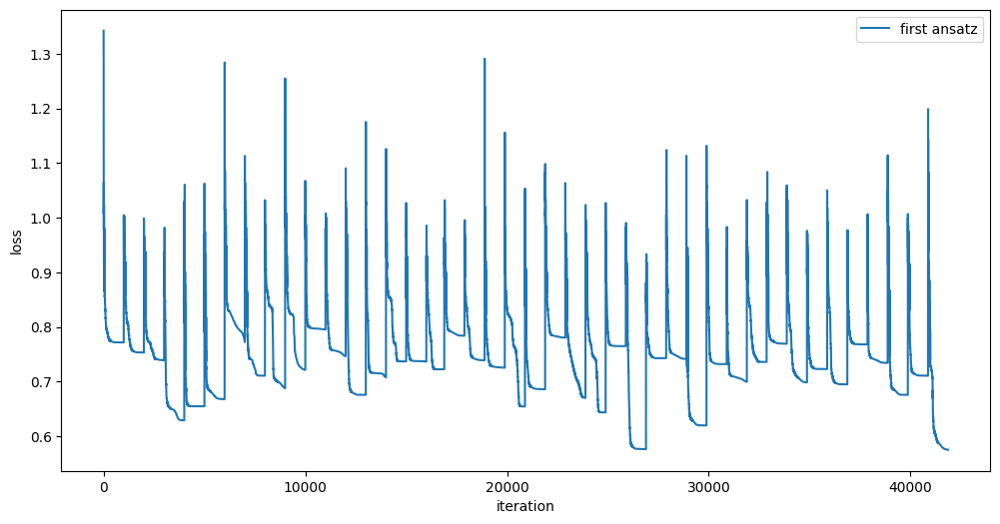

In [38]:
obj_func_vals_first = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_first, label="first ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

## Modelo A

In [39]:
X_small = X_scaled[:2000]
y_small = y_bin[:2000]

iter_count = 0
max_iter = 300

callback_loss_history = []

def callback(xk):
    global iter_count
    iter_count += 1
    
    current_loss = loss(xk, qc, theta, x_params, X_small, y_small)
    
    callback_loss_history.append(current_loss)
    
    print(f"Iteración {iter_count}/{max_iter} | Loss: {current_loss:.4f}")


counts = Counter(y_small)

w_FM = 1 / counts[1]
w_AFM = 1 / counts[-1]

print(f"Pesos: FM={w_FM:.3f}, AFM={w_AFM:.3f}")

qc, theta, x_params = circuito_vqccc()

theta_init = np.random.uniform(0, 2*np.pi, len(theta))

res = minimize(
    loss,
    theta_init,
    args=(qc, theta, x_params, X_small, y_small),
    method='COBYLA',
    callback=callback,
    options={'maxiter': max_iter}
)

theta_opt = res.x

Pesos: FM=0.001, AFM=0.002


KeyboardInterrupt: 

## Modelo B

In [ ]:
iter_count = 0
max_iter = 40
def callback(xk):
    global iter_count
    iter_count += 1
    
    current_loss = loss(xk, qc, theta, x_params, X_small, y_small)
    
    print(f"Iter {iter_count}/{max_iter} | Loss: {current_loss:.4f}")


In [9]:
counts = Counter(y_small)
w_FM = 1 / counts[1]
w_AFM = 1 / counts[-1]
print(f"Pesos: FM={w_FM:.3f}, AFM={w_AFM:.3f}")

qc, theta, x_params = circuito_vqccc()

theta_init = np.random.uniform(0, 2*np.pi, len(theta))

res = minimize(
    loss,
    theta_init,
    args=(qc, theta, x_params, X_small, y_small),
    method='COBYLA',
    options={'maxiter': 200}
)

theta_opt = res.x

Pesos: FM=0.001, AFM=0.001
Loss: 0.994136
Loss: 0.991479
Loss: 0.997382
Loss: 1.026947
Loss: 0.996550
Loss: 0.980376
Loss: 0.992109
Loss: 1.005109
Loss: 1.001949
Loss: 0.981669
Loss: 0.985673
Loss: 0.983529
Loss: 0.983921
Loss: 0.983605
Loss: 0.974135
Loss: 0.981989
Loss: 0.978922
Loss: 0.997333
Loss: 0.988508
Loss: 0.988963
Loss: 0.971837
Loss: 0.986177
Loss: 0.972519
Loss: 0.984334
Loss: 1.001172
Loss: 0.972870
Loss: 0.984502
Loss: 0.991918
Loss: 0.991637
Loss: 0.991847
Loss: 0.979124
Loss: 1.002922
Loss: 0.973411
Loss: 0.975562
Loss: 0.994984
Loss: 0.971044
Loss: 0.978592
Loss: 0.975746
Loss: 0.988999
Loss: 0.987458
Loss: 0.989208
Loss: 0.969388
Loss: 0.989864
Loss: 0.975332
Loss: 0.969430
Loss: 0.974728
Loss: 0.981716
Loss: 0.981711
Loss: 0.972462
Loss: 0.974041
Loss: 1.000460
Loss: 0.975191
Loss: 0.955872
Loss: 0.962774
Loss: 0.970120
Loss: 0.971314
Loss: 0.966215
Loss: 0.960967
Loss: 0.969296
Loss: 0.978361
Loss: 0.967439
Loss: 0.973817
Loss: 0.964008
Loss: 0.959145
Loss: 0.96767

In [11]:
plt.figure(figsize=(8,5))

plt.plot(loss_history, color="blue", label="Loss")
plt.scatter(range(len(loss_history)), loss_history, s=10)

plt.xlabel("Evaluaciones")P
plt.ylabel("Loss")
plt.title("Loss vs Evaluaciones")

plt.legend()
plt.grid(True)
plt.show()

SyntaxError: invalid syntax (802289912.py, line 6)

## Modelo C

In [ ]:
counts = Counter(y_small)
w_FM = 1 / counts[1]
w_AFM = 1 / counts[-1]

qc, theta, x_params = circuito_vqccc()

np.random.seed(42)
theta_init = np.random.uniform(-0.1, 0.1, len(theta))

loss_history = []

res = minimize(
    loss,
    theta_init,
    args=(qc, theta, x_params, X_small, y_small),
    method='COBYLA',
    options={'maxiter': 200}
)

theta_opt = res.x

Loss: 1.028889
Loss: 1.024734
Loss: 1.030690
Loss: 1.028680
Loss: 1.028449
Loss: 1.028758


KeyboardInterrupt: 

## Prueba con datos desconocidos

In [19]:
# ==============================
# PRUEBA DEL MODELO ENTRENADO EN BLOQUE 3
# ==============================

ruta3 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_3.csv"

dfC3 = pd.read_csv(ruta3)

print("Distribución original bloque 3:")
print(dfC3["magnetic_label"].value_counts())

# Separar clases
df_FMA = dfC3[dfC3["magnetic_label"] == "FM"]
df_AFMA = dfC3[dfC3["magnetic_label"] == "AFM"]

# Balanceo con la clase minoritaria
n_min = min(len(df_FMA), len(df_AFMA))

df_FM_bal = df_FMA.sample(n=n_min, random_state=42)
df_AFM_bal = df_AFMA.sample(n=n_min, random_state=42)

dfPRUEBA = pd.concat([df_FM_bal, df_AFM_bal]).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("\nDistribución balanceada dfPRUEBA:")
print(dfPRUEBA["magnetic_label"].value_counts())
print("Shape dfPRUEBA:", dfPRUEBA.shape)

Distribución original bloque 3:
magnetic_label
FM     1353
AFM     646
Name: count, dtype: int64

Distribución balanceada dfPRUEBA:
magnetic_label
FM     646
AFM    646
Name: count, dtype: int64
Shape dfPRUEBA: (1292, 95)


In [20]:
# ==============================
# PREPARAR DATOS DE PRUEBA
# ==============================

X_prueba = dfPRUEBA.drop(columns=["magnetic_label"])

# asegurar mismo orden de columnas que en entrenamiento
X_prueba = X_prueba[X.columns]

# usar el MISMO scaler entrenado antes
X_prueba_scaled = scaler.transform(X_prueba)

# FM -> 1, AFM -> -1
y_prueba = np.array([1 if label == "FM" else -1 for label in dfPRUEBA["magnetic_label"]])

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

In [89]:
# ==============================
# PREDICCIONES SOBRE dfPRUEBA
# ==============================

preds_prueba_raw = []

for i in range(len(X_prueba_scaled)):
    pred = forward(qc, theta_opt, X_prueba_scaled[i], theta, x_params)
    preds_prueba_raw.append(pred)

preds_prueba_raw = np.array(preds_prueba_raw)

# Convertir salida continua [-1, 1] a clases
preds_prueba = np.where(preds_prueba_raw >= 0.05, 1, -1)

print("Primeras predicciones:")
for i in range(10):
    print(f"Real: {y_prueba[i]} | Pred: {preds_prueba[i]} | Raw: {preds_prueba_raw[i]:.3f}")

Primeras predicciones:
Real: 1 | Pred: 1 | Raw: 0.125
Real: 1 | Pred: -1 | Raw: -0.141
Real: 1 | Pred: 1 | Raw: 0.305
Real: 1 | Pred: -1 | Raw: -0.062
Real: 1 | Pred: 1 | Raw: 0.297
Real: -1 | Pred: -1 | Raw: 0.023
Real: 1 | Pred: -1 | Raw: -0.031
Real: 1 | Pred: 1 | Raw: 0.289
Real: 1 | Pred: -1 | Raw: -0.227
Real: 1 | Pred: 1 | Raw: 0.289


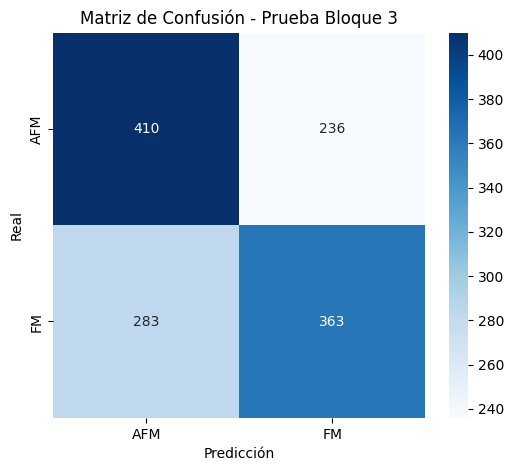

              precision    recall  f1-score   support

         AFM       0.59      0.63      0.61       646
          FM       0.61      0.56      0.58       646

    accuracy                           0.60      1292
   macro avg       0.60      0.60      0.60      1292
weighted avg       0.60      0.60      0.60      1292



In [90]:
# ==============================
# MATRIZ DE CONFUSIÓN
# ==============================

cm = confusion_matrix(y_prueba, preds_prueba)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["AFM", "FM"],
    yticklabels=["AFM", "FM"]
)

plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión - Prueba Bloque 3")
plt.show()

print(classification_report(y_prueba, preds_prueba, target_names=["AFM", "FM"]))

## Modelos con codificacion de amplitud

In [40]:
def load_data(data_path: str) -> Tuple[pd.DataFrame, str]:
    """Load data from pickle or parquet format."""
    if data_path.endswith(".pkl") or data_path.endswith(".pickle"):
        return pd.read_pickle(data_path), "PICKLE"
    
def process_embeddings(df: pd.DataFrame, file_format: str) -> pd.DataFrame:
    if "embedding" not in df.columns:
        raise ValueError("Column 'embedding' not found in the dataframe.")

    if file_format in ("PICKLE", "PARQUET"):
        df["emb_array"] = df["embedding"].apply(lambda x: np.array(x, dtype=np.float32))

    return df

def get_insurance_column(df: pd.DataFrame) -> str:
    for col in ["new_insurance_type", "insurance", "insurance_type"]:
        if col in df.columns:
            return col
    raise ValueError("No insurance column found. Expected one of: new_insurance_type, insurance, insurance_type")
def data_prepare_cv(n_qubits, X_train, X_other):
    """
    Escala los datos y aplica PCA para reducir la dimensionalidad al número de qubits.
    
    El ajuste (fit) se hace SOLO con X_train para evitar fuga de información.
    Luego se transforma tanto X_train como el otro conjunto (validación o test).
    
    Parámetros
    ----------
    n_qubits : int
        Número de componentes principales (dimensión final para el modelo cuántico)
    X_train : np.ndarray
        Datos de entrenamiento
    X_other : np.ndarray
        Datos de validación o prueba

    Retorna
    -------
    X_train_pca : np.ndarray
        Datos de entrenamiento escalados y reducidos
    X_other_pca : np.ndarray
        Datos del otro conjunto transformados con el mismo escalador y PCA
    """

    # 1️⃣ Escalado (media 0, varianza 1) — se ajusta SOLO con train
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_other_scaled = scaler.transform(X_other)

    # 2️⃣ Reducción de dimensionalidad con PCA al número de qubits
    pca = PCA(n_components=n_qubits)
    X_train_pca = pca.fit_transform(X_train_scaled)#Aprende usando solo los datos de entrenamiento
    X_other_pca = pca.transform(X_other_scaled) #Aquí solo se aplica el mismo PCA aprendido con entrenamiento.

    return X_train_pca, X_other_pca

def amplitude_normalization(data: np.array, target_dim) -> np.array:
    # Normalizar cada fila del dataset para que su "largo" sea 1
    # keepdims=True es vital para que pueda dividir correctamente l a matriz
    normas = np.linalg.norm(data, axis=1, keepdims=True)
    print(normas.max())
    # Dividimos cada dato por la norma de su fila
    dataset_normalizado = data / normas
    #dataset_normalizado=[matriz[i]/np.sqrt(np.sum(matriz[i]**2)) for i in range(matriz.shape[0])]
    #rellenar con ceros (Padding)
    # Crea una matriz de ceros del tamaño objetivo
    padded = np.zeros((len(dataset_normalizado), target_dim))
    # Copia los datos originales
    padded[:, :dataset_normalizado.shape[1]] = dataset_normalizado
    return padded

In [42]:
seed = 42

n_qubits = 7
max_samples = 2564

# Usas directamente tu df2
df = df2.copy()

#  1. Definir columna objetivo (ya no es insurance)
target_col = "magnetic_label"

# 2. Limpiar NaNs
df = df.dropna().copy()

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y = le.fit_transform(df[target_col].astype(str).values)

# Convertir a ±1 para tu modelo cuántico
y[y == 0] = -1

# Guardar nombres de clases (opcional)
class_names = ["AFM", "FM"]  # ajusta si es necesario
global_class_names = class_names

#  4. Crear X (features)
X = df.drop(columns=[target_col]).values.astype(np.float32)

# Guardar forma original
original_shape = X.shape

print("Shape original:", X.shape)
print("maximo:", X.max(), " minimo:", X.min())

NameError: name 'df2' is not defined

In [43]:
X_p=np.abs(X)
print(X_p.max(), "   ", X_p.min())
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

avg_atomic_number         96.000000
avg_atomic_weight        247.000000
avg_electronegativity      3.980000
L2_stoichiometry           1.000000
composition_entropy        1.791759
                            ...    
p_Zn                       0.894737
p_Zr                       0.500000
avg_group                 17.000000
avg_period                 7.000000
avg_magnetic_moment        2.110663
Length: 94, dtype: float64     avg_atomic_number        2.875706
avg_atomic_weight        5.132519
avg_electronegativity    1.100000
L2_stoichiometry         0.166667
composition_entropy      0.000000
                           ...   
p_Zn                     0.000000
p_Zr                     0.000000
avg_group                1.400000
avg_period               1.355932
avg_magnetic_moment      0.000000
Length: 94, dtype: float64


In [44]:
def pad_to_power_of_two(X, n_qubits):
    target_dim = 2**n_qubits
    padded = np.zeros((X.shape[0], target_dim), dtype=np.float32)
    padded[:, :X.shape[1]] = X
    return padded

X = pad_to_power_of_two(X, n_qubits)

In [45]:
X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-10)

In [46]:
X_p=np.abs(X)
print(X_p.max(), "   ", X_p.min())

0.9982809     0.0


In [48]:
pca_features=0 #poner cero si no se quiere realizar PCA
# Create indices for tracking samples

indices = np.arange(len(X))

# Split: 80% train, 20% temp
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X, y, indices, test_size=0.2, stratify=y, random_state=seed
)

# Split temp: 50% val, 50% test (10% each of original)
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.5, stratify=y_temp, random_state=seed
)
# Apply PCA and scaling
if pca_features>1:
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    X_val_scaled = scaler.transform(X_val)
    if len(X_rest)>0:
        X_rest_scaled = scaler.transform(X_rest)

    pca = PCA(n_components=pca_features)

    X_train = pca.fit_transform(X_train_scaled)#Aprende usando solo los datos de entrenamiento
    X_test = pca.transform(X_test_scaled)
    X_val = pca.transform(X_val_scaled)
    if len(X_rest)>0:
        X_rest = pca.transform(X_rest_scaled)

In [49]:
num_features = X_train.shape[1]
n_qubits = int(np.ceil(np.log2(num_features)))
dim_target = 2**n_qubits

print(f"Features: {num_features} -> Qubits necesarios: {n_qubits}")

X_train = amplitude_normalization(X_train, dim_target)
X_val   = amplitude_normalization(X_val, dim_target)
X_test  = amplitude_normalization(X_test, dim_target)

Features: 128 -> Qubits necesarios: 7
1.0000001
1.0000001
1.0000001


In [50]:
X_train_p=np.abs(X_train)
print(X_train_p.max(), "   ", X_train_p.min())

0.9966024160385132     0.0


C:\Users\javie\AppData\Local\Temp\ipykernel_19100\2847394999.py:1: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=n_qubits,reps=3,entanglement="circular")


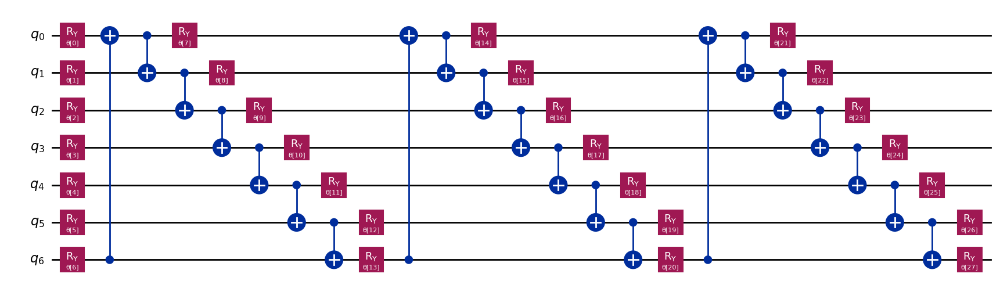

In [51]:
ansatz = RealAmplitudes(num_qubits=n_qubits,reps=3,entanglement="circular")
#ansatz = EfficientSU2(num_qubits=n_qubits, reps=1, entanglement='circular')
#ansatz = ZFeatureMap(feature_dimension=n_qubits, reps=1)
ansatz.decompose().draw('mpl')

In [52]:
#observable = SparsePauliOp.from_list([("Z" * (n_qubits), 1)])
observable = SparsePauliOp.from_list([("I" * (n_qubits - 1) + "Z", 1)])

In [53]:
# Esta versión de forward esta optimizada
def forward(
    input_data: np.ndarray,
    weight_params: np.ndarray,
    estimator,
    observable,
) -> np.ndarray:
    """
    Forward pass para amplitude encoding usando Initialize.
    Cada muestra se carga como estado cuántico.
    """

    predictions = []
    pubs = []

    for sample in input_data:
        amplitudes = sample / np.linalg.norm(sample)
        qc = QuantumCircuit(n_qubits)

        qc.initialize(amplitudes, range(n_qubits))
        qc.compose(ansatz, inplace=True)
        pubs.append((qc, observable, weight_params))
    job = estimator.run(pubs)
    result = job.result()
    predictions = [res.data.evs for res in result]

    return np.array(predictions).reshape(-1)
def mse_loss_weights(weight_params):
    preds = forward(input_params, weight_params, estimator, observable)

    preds = preds.reshape(-1)
    target_vec = np.array(target).reshape(-1)

    loss = np.mean((preds - target_vec) ** 2)
    print("predicciones: ",preds[0:50])
    
    objective_func_vals.append(float(loss))
    
    global iter
    
    
    #if iter % 50 == 0:
    if iter % 1 == 0:
        print(f"Iteración {iter} | Loss = {loss:.6f}")

    iter += 1


    return float(loss)


## Modelo A

Se uso: 

ansatz = RealAmplitudes(num_qubits=n_qubits,reps=3,entanglement="circular")
observable = SparsePauliOp.from_list([("I" * (n_qubits - 1) + "Z", 1)])

In [55]:
observables = observable
# input_params = train_images_batch
# target = train_labels_batch
objective_func_vals = []
iter = 0
batch_size =500  # puede ser menor a esto
num_epochs = 3
num_samples = len(X_train)

estimator = Estimator() 

print(num_samples)

# Random initial weights for the ansatz
np.random.seed(42)
#weight_params = np.random.rand(len(ansatz.parameters)) * 2 * np.pi
weight_params = np.random.uniform(-0.15, 0.15, len(ansatz.parameters))
print(weight_params)

for epoch in range(num_epochs):
    for i in range((num_samples - 1) // batch_size + 1):
        print(f"Epoch: {epoch}, batch: {i}")
        start_i = i * batch_size
        end_i = start_i + batch_size
        X_train_batch = np.array(X_train[start_i:end_i])
        y_train_batch = np.array(y_train[start_i:end_i])
        input_params = X_train_batch
        target = y_train_batch
        iter = 0
        res = minimize(
            mse_loss_weights, weight_params, method="cobyla", options={"maxiter": 200}
        )
        weight_params = res["x"]

6396
[-0.03763796  0.13521429  0.06959818  0.02959755 -0.10319441 -0.10320164
 -0.13257492  0.10985284  0.0303345   0.06242177 -0.14382465  0.14097296
  0.09973279 -0.08629827 -0.09545251 -0.09497865 -0.05872733  0.00742693
 -0.02041649 -0.06263126  0.03355587 -0.10815184 -0.06235661 -0.04009145
 -0.013179    0.08555279 -0.09009787  0.00427033]
Epoch: 0, batch: 0


TypeError: unsupported operand type(s) for -: 'float' and 'str'

### Guardamos el modelo

In [45]:
import os
import pickle
import numpy as np

# Ruta donde quieres guardar el modelo
ruta_modelo = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"

# Crear la carpeta si no existe
os.makedirs(ruta_modelo, exist_ok=True)

# Diccionario con todo lo importante del modelo
modelo_guardado = {
    "weight_params": weight_params,
    "n_qubits": n_qubits,
    "dim_target": dim_target,
    "ansatz": ansatz,
    "observable": observable,
    "objective_func_vals": objective_func_vals,
    "batch_size": batch_size,
    "num_epochs": num_epochs
}

# Nombre del archivo
archivo_modelo = os.path.join(ruta_modelo, "modelo_cuantico_bloque_entrega6.pkl")

# Guardar
with open(archivo_modelo, "wb") as f:
    pickle.dump(modelo_guardado, f)

print("Modelo guardado correctamente en:")
print(archivo_modelo)

Modelo guardado correctamente en:
C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6\modelo_cuantico_bloque_entrega6.pkl


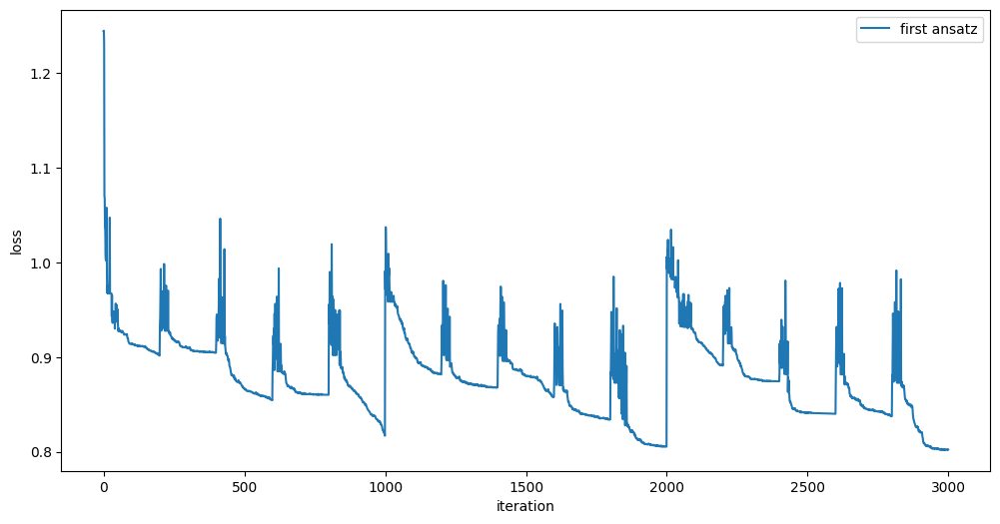

In [21]:
obj_func_vals_first = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_first, label="first ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predicciones sobre el conjunto de prueba
y_pred_continuo = forward(
    np.array(X_test),
    weight_params,
    estimator,
    observable
)

 
# Asegurar que y_test también esté en formato -1 y 1
y_true = np.array(y_test).reshape(-1)

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred, labels=[1, -1])

print("Matriz de confusión:")
print(cm)

print("\nReporte de clasificación:")
print(classification_report(
    y_true,
    y_pred,
    labels=[1, -1],
    target_names=["FM", "AFM"]
))

Matriz de confusión:
[[70 59]
 [59 71]]

Reporte de clasificación:
              precision    recall  f1-score   support

          FM       0.54      0.54      0.54       129
         AFM       0.55      0.55      0.55       130

    accuracy                           0.54       259
   macro avg       0.54      0.54      0.54       259
weighted avg       0.54      0.54      0.54       259



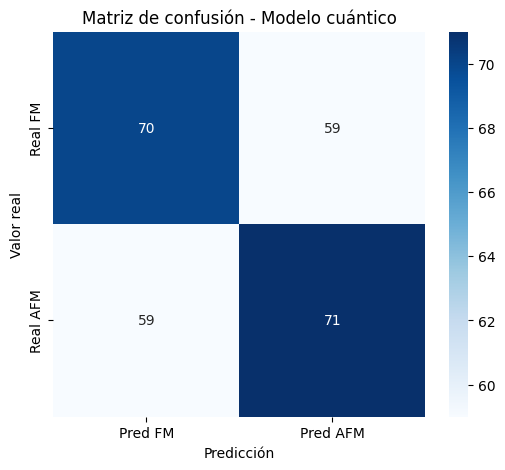

In [32]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred FM", "Pred AFM"],
    yticklabels=["Real FM", "Real AFM"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Modelo cuántico")
plt.show()

Como observaciones se tiene que el ultimo batch de cada epoca es el que mas rapido realia las iteraciones, y que mayor disminucion de la funcion de perdida evidencia, es por tanto que se propone un modelo con mas iteraciones, manteniendo el mismo batch (incluir luego y dataset mayor)

## Modelo B

Similar al anterior, solo que se disminuye el numero de epocas a 2, y se aumenta al doble de iteraciones por epoca

In [16]:
observables = observable
# input_params = train_images_batch
# target = train_labels_batch
objective_func_vals = []
iter = 0
batch_size =250  # puede ser menor a esto
num_epochs =4
num_samples = len(X_train)

estimator = Estimator() 

print(num_samples)

# Random initial weights for the ansatz
np.random.seed(42)
#weight_params = np.random.rand(len(ansatz.parameters)) * 2 * np.pi
weight_params = np.random.uniform(-0.1, 0.1, len(ansatz.parameters))
print(weight_params)

for epoch in range(num_epochs):
    for i in range((num_samples - 1) // batch_size + 1):
        print(f"Epoch: {epoch}, batch: {i}")
        start_i = i * batch_size
        end_i = start_i + batch_size
        X_train_batch = np.array(X_train[start_i:end_i])
        y_train_batch = np.array(y_train[start_i:end_i])
        input_params = X_train_batch
        target = y_train_batch
        iter = 0
        res = minimize(
            mse_loss_weights, weight_params, method="cobyla", options={"maxiter": 600}
        )
        weight_params = res["x"]

3100
[-0.02509198  0.09014286  0.04639879  0.0197317  -0.06879627 -0.0688011
 -0.08838328  0.07323523  0.020223    0.04161452 -0.0958831   0.09398197
  0.06648853 -0.05753218 -0.06363501 -0.0633191  -0.03915155  0.00495129
 -0.013611   -0.04175417  0.02237058 -0.07210123 -0.04157107 -0.02672763
 -0.008786    0.05703519 -0.06006524  0.00284689]
Epoch: 0, batch: 0
predicciones:  [ 0.53317631  0.92110998  0.30193833  0.42584729  0.3419762   0.60398963
 -0.82034864 -0.77527353 -0.61715708 -0.66412282 -0.8597979  -0.33809701
 -0.59451055 -0.15389968  0.32929468  0.86751981 -0.11696207 -0.67904707
 -0.31611843 -0.27086505  0.47044752 -0.71171573  0.61978073  0.79152596
  0.19376637  0.69463746  0.56337428  0.38022471  0.53324485 -0.71239918
 -0.0508823  -0.74818188 -0.75750857  0.08143934 -0.75210181 -0.74194838
 -0.77442037 -0.49361269  0.63269623  0.46165851 -0.27920446  0.42182624
  0.37261038 -0.72852194 -0.65504656 -0.43753606  0.74732142 -0.15411647
  0.26878098  0.46630302]
Iteración 

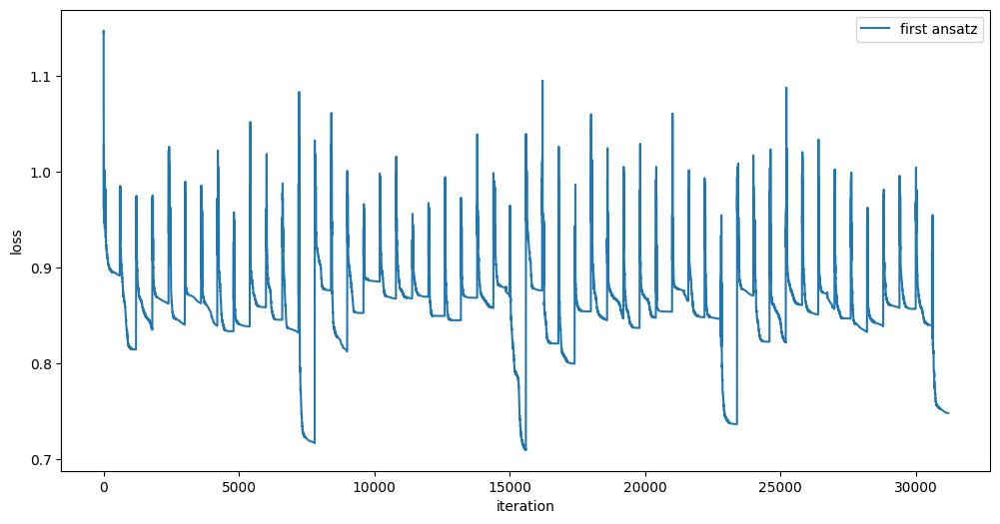

In [17]:
obj_func_vals_first = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_first, label="first ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

In [21]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Predicciones sobre el conjunto de prueba
y_pred_continuo = forward(
    np.array(X_test),
    weight_params,
    estimator,
    observable
)
y_pred = np.where(y_pred_continuo >= 0, 1, -1)
 
# Asegurar que y_test también esté en formato -1 y 1
y_true = np.array(y_test).reshape(-1)

# Matriz de confusión
cm = confusion_matrix(y_true, y_pred, labels=[1, -1])

print("Matriz de confusión:")
print(cm)

print("\nReporte de clasificación:")
print(classification_report(
    y_true,
    y_pred,
    labels=[1, -1],
    target_names=["FM", "AFM"]
))

Matriz de confusión:
[[131  63]
 [ 81 113]]

Reporte de clasificación:
              precision    recall  f1-score   support

          FM       0.62      0.68      0.65       194
         AFM       0.64      0.58      0.61       194

    accuracy                           0.63       388
   macro avg       0.63      0.63      0.63       388
weighted avg       0.63      0.63      0.63       388



## Prueba con datos desconocidos

Distribución original bloque 3:
magnetic_label
FM     1353
AFM     646
Name: count, dtype: int64

Distribución balanceada dfPRUEBA:
magnetic_label
FM     646
AFM    646
Name: count, dtype: int64
Shape dfPRUEBA: (1292, 95)

Shape X_prueba antes de normalizar: (1292, 94)
Shape y_prueba: (1292,)
261.454

Shape X_prueba después de amplitude normalization: (1292, 128)

Primeras predicciones continuas:
[0.3236465  0.32193624 0.31942284 0.3204407  0.30641912 0.32240197
 0.31896638 0.32287059 0.31770949 0.29955845 0.31894771 0.31913074
 0.32302129 0.32268248 0.32201334 0.31751385 0.32297134 0.3231329
 0.30076094 0.31886328]

Primeras predicciones clasificadas:
[ 1  1 -1 -1 -1  1 -1  1 -1 -1 -1 -1  1  1  1 -1  1  1 -1 -1]

Primeros valores reales:
[ 1  1  1  1  1 -1  1  1  1  1 -1  1  1 -1 -1  1 -1 -1  1  1]

Matriz de confusión:
[[223 423]
 [325 321]]

Reporte de clasificación:
              precision    recall  f1-score   support

          FM       0.41      0.35      0.37       646
        

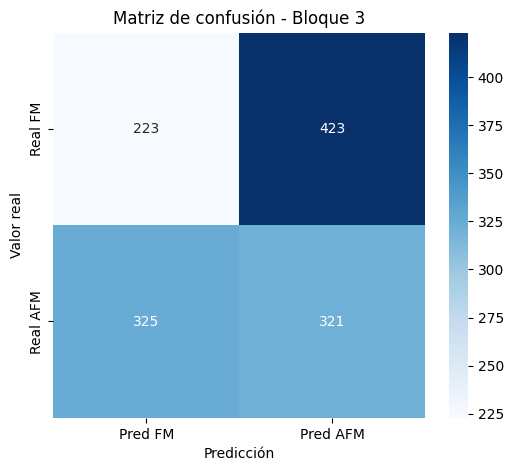

In [41]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# ==============================
# PRUEBA DEL MODELO ENTRENADO EN BLOQUE 3
# ==============================

ruta3 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_4.csv"

dfC3 = pd.read_csv(ruta3)

print("Distribución original bloque 3:")
print(dfC3["magnetic_label"].value_counts())

# ==============================
# BALANCEAR BLOQUE 3
# ==============================

df_FM = dfC3[dfC3["magnetic_label"] == "FM"]
df_AFM = dfC3[dfC3["magnetic_label"] == "AFM"]

n_min = min(len(df_FM), len(df_AFM))

df_FM_bal = df_FM.sample(n=n_min, random_state=42)
df_AFM_bal = df_AFM.sample(n=n_min, random_state=42)

dfPRUEBA = pd.concat([df_FM_bal, df_AFM_bal]).sample(
    frac=1, random_state=42
).reset_index(drop=True)

print("\nDistribución balanceada dfPRUEBA:")
print(dfPRUEBA["magnetic_label"].value_counts())
print("Shape dfPRUEBA:", dfPRUEBA.shape)

# ==============================
# SEPARAR X E y
# ==============================

target_col = "magnetic_label"

X_prueba = dfPRUEBA.drop(columns=[target_col]).values.astype(np.float32)

# Convertir etiquetas:
# FM  ->  1
# AFM -> -1
y_prueba = dfPRUEBA[target_col].map({
    "FM": 1,
    "AFM": -1
}).values

print("\nShape X_prueba antes de normalizar:", X_prueba.shape)
print("Shape y_prueba:", y_prueba.shape)

# ==============================
# APLICAR MISMA PREPARACIÓN
# ==============================

# IMPORTANTE:
# Como en tu entrenamiento pca_features = 0, entonces NO aplicaste PCA.
# Solo debes hacer amplitude_normalization con la misma dim_target.

X_prueba = amplitude_normalization(X_prueba, dim_target)

print("\nShape X_prueba después de amplitude normalization:", X_prueba.shape)

# ==============================
# PREDICCIÓN CON MODELO CUÁNTICO
# ==============================

y_pred_continuo = forward(
    X_prueba,
    weight_params,
    estimator,
    observable
)

print("\nPrimeras predicciones continuas:")
print(y_pred_continuo[:20])

# ==============================
# CONVERTIR A CLASES
# ==============================

# Si predicción >= 0 se toma como FM
# Si predicción < 0 se toma como AFM
y_pred = np.where(y_pred_continuo >= 0.32103, 1, -1)

print("\nPrimeras predicciones clasificadas:")
print(y_pred[:20])

print("\nPrimeros valores reales:")
print(y_prueba[:20])

# ==============================
# MATRIZ DE CONFUSIÓN
# ==============================

cm = confusion_matrix(
    y_prueba,
    y_pred,
    labels=[1, -1]
)

print("\nMatriz de confusión:")
print(cm)

print("\nReporte de clasificación:")
print(classification_report(
    y_prueba,
    y_pred,
    labels=[1, -1],
    target_names=["FM", "AFM"]
))

# ==============================
# GRAFICAR MATRIZ DE CONFUSIÓN
# ==============================

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred FM", "Pred AFM"],
    yticklabels=["Real FM", "Real AFM"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Bloque 3")
plt.show()

Segun el modelo a, se debio ajustar la frontera de desicion en # Convertir predicciones continuas a clases -1 y 1
y_pred = np.where(y_pred_continuo >= 0.09, 1, -1) y se obtuvo con esto una matriz de confusion mas o menos simetricas
mientras que en la prueba con datos nuevos se  una frontera de desicion alrededor de los y_pred = np.where(y_pred_continuo >= 0.075, 1, -1) para obtener una matriz de confusion no tan simetrica lo cual muestra una baja generalizacion del modelo
de esta manera obteniendo

In [3]:
ruta1 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_1.csv"  
ruta2 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_2.csv"
ruta3 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_3.csv"
dfC1 = pd.read_csv(ruta1)
dfC2 = pd.read_csv(ruta2)
dfC3 = pd.read_csv(ruta3)
df = pd.concat([dfC1, dfC2, dfC3], ignore_index=True)
# Ver distribución original
print("Distribución original:")
print(df["magnetic_label"].value_counts())

# Separar clases
df_FM = df[df["magnetic_label"] == "FM"]
df_AFM = df[df["magnetic_label"] == "AFM"]

# Tamaño de la clase minoritaria
n_min = min(len(df_FM), len(df_AFM))

# Balanceo (undersampling)
df_FM_bal = df_FM.sample(n=n_min, random_state=42)
df_AFM_bal = df_AFM.sample(n=n_min, random_state=42)

# Unir y mezclar
df2 = pd.concat([df_FM_bal, df_AFM_bal]).sample(frac=1, random_state=42).reset_index(drop=True)

print("\nDistribución balanceada:")
print(df2["magnetic_label"].value_counts())
print("Shape df2:", df2.shape)

Distribución original:
magnetic_label
FM     4059
AFM    1938
Name: count, dtype: int64

Distribución balanceada:
magnetic_label
AFM    1938
FM     1938
Name: count, dtype: int64
Shape df2: (3876, 95)


In [4]:

y = df2["magnetic_label"]
X = df2.drop(columns=["magnetic_label"])
scaler = MinMaxScaler(feature_range=(0, np.pi))  # 0 a π
X_scaled = scaler.fit_transform(X)
# FM → +1, AFM → -1
y_bin = np.array([1 if label == "FM" else -1 for label in y])

In [6]:

y = df2["magnetic_label"]
X = df2.drop(columns=["magnetic_label"])
scaler = MinMaxScaler(feature_range=(0, np.pi))  # 0 a π
X_scaled = scaler.fit_transform(X)
# FM → +1, AFM → -1
y_bin = np.array([1 if label == "FM" else -1 for label in y])

In [7]:


sim = AerSimulator()
X_small = X_scaled[:2000]
y_small = y_bin[:2000]

sim = AerSimulator()

def forward(qc, theta_vals, x_vals, theta, x_params, shots=256):

    bind_dict = {}

    # asignar theta
    for t, val in zip(theta, theta_vals):
        bind_dict[t] = val

    # asignar x
    for xp, val in zip(x_params, x_vals):
        bind_dict[xp] = val

    qc_bound = qc.assign_parameters(bind_dict)
    qc_bound.measure_all()

    result = sim.run(qc_bound, shots=shots).result()
    counts = result.get_counts()

    prob_1 = sum(v for k,v in counts.items() if k[-1] == '1') / shots

    return 1 - 2*prob_1

In [8]:
iter_count = 0
max_iter = 40
def callback(xk):
    global iter_count
    iter_count += 1
    
    current_loss = loss(xk, qc, theta, x_params, X_small, y_small)
    
    print(f"Iter {iter_count}/{max_iter} | Loss: {current_loss:.4f}")


## Abrir modelos cargados

In [2]:
import joblib
import os

ruta_modelos = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"
nombre_modelo = "modelo_cuanticoB1_bloque_entrega6.pkl"

ruta_modelo = os.path.join(ruta_modelos, nombre_modelo)

modelo = joblib.load(ruta_modelo)

print(type(modelo))
nombre_modelo = "modelo_cuantico_bloque_entrega6.pkl"

<class 'dict'>


In [3]:
modelo.keys()

dict_keys(['weight_params', 'n_qubits', 'dim_target', 'ansatz', 'observable', 'objective_func_vals', 'batch_size', 'num_epochs'])

Qubits: 7
Dimensión objetivo: 128
Cantidad de pesos entrenados: 28
Batch size: 250
Epochs: 4
Observable: SparsePauliOp(['IIIIIIZ'],
              coeffs=[1.+0.j])


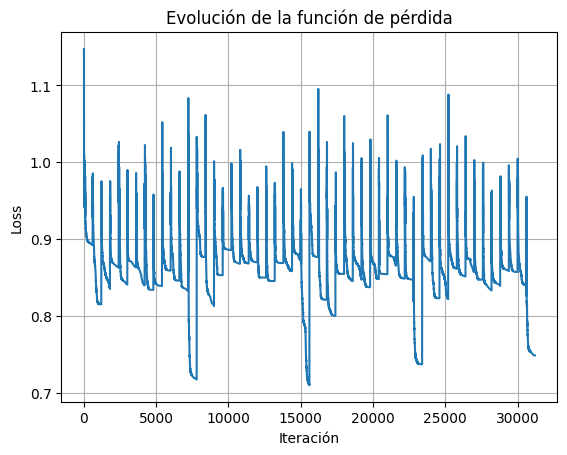

In [4]:
weight_params = modelo["weight_params"]
n_qubits = modelo["n_qubits"]
dim_target = modelo["dim_target"]
ansatz = modelo["ansatz"]
observable = modelo["observable"]
objective_func_vals = modelo["objective_func_vals"]
batch_size = modelo["batch_size"]
num_epochs = modelo["num_epochs"]

print("Qubits:", n_qubits)
print("Dimensión objetivo:", dim_target)
print("Cantidad de pesos entrenados:", len(weight_params))
print("Batch size:", batch_size)
print("Epochs:", num_epochs)
print("Observable:", observable)
import matplotlib.pyplot as plt

plt.plot(objective_func_vals)
plt.xlabel("Iteración")
plt.ylabel("Loss")
plt.title("Evolución de la función de pérdida")
plt.grid()
plt.show()

In [5]:
import joblib
import os

ruta_modelos = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"
nombre_modelo = "modelo_cuanticoB1_bloque_entrega6.pkl"

ruta_modelo = os.path.join(ruta_modelos, nombre_modelo)

modelo = joblib.load(ruta_modelo)

print(type(modelo))
nombre_modelo = "modelo_cuanticoB1_bloque_entrega6.pkl"

<class 'dict'>


Qubits: 7
Dimensión objetivo: 128
Cantidad de pesos entrenados: 28
Batch size: 250
Epochs: 4
Observable: SparsePauliOp(['IIIIIIZ'],
              coeffs=[1.+0.j])


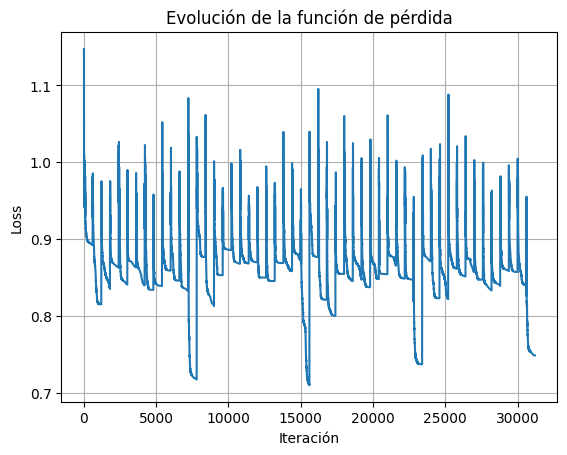

In [6]:
weight_params = modelo["weight_params"]
n_qubits = modelo["n_qubits"]
dim_target = modelo["dim_target"]
ansatz = modelo["ansatz"]
observable = modelo["observable"]
objective_func_vals = modelo["objective_func_vals"]
batch_size = modelo["batch_size"]
num_epochs = modelo["num_epochs"]

print("Qubits:", n_qubits)
print("Dimensión objetivo:", dim_target)
print("Cantidad de pesos entrenados:", len(weight_params))
print("Batch size:", batch_size)
print("Epochs:", num_epochs)
print("Observable:", observable)
import matplotlib.pyplot as plt

plt.plot(objective_func_vals)
plt.xlabel("Iteración")
plt.ylabel("Loss")
plt.title("Evolución de la función de pérdida")
plt.grid()
plt.show()

In [9]:
import joblib
import os

ruta_modelos = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"
nombre_modelo = "modelo_cuanticoB1_bloque_entrega6.pkl"

ruta_modelo = os.path.join(ruta_modelos, nombre_modelo)

modelo = joblib.load(ruta_modelo)

print(type(modelo))
nombre_modelo = "modelo_cuanticoC_bloque_entrega6.pkl"

<class 'dict'>


In [11]:
import joblib
import os

ruta_modelos = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"
nombre_modelo = "modelo_cuanticoC_bloque_entrega6.pkl"

ruta_modelo = os.path.join(ruta_modelos, nombre_modelo)

modelo = joblib.load(ruta_modelo)

print(type(modelo))
nombre_modelo = "modelo_cuanticoC_bloque_entrega6.pkl"

<class 'dict'>


Qubits: 7
Dimensión objetivo: 128
Cantidad de pesos entrenados: 28
Batch size: 50
Epochs: 1
Observable: SparsePauliOp(['IIIIIIZ'],
              coeffs=[1.+0.j])


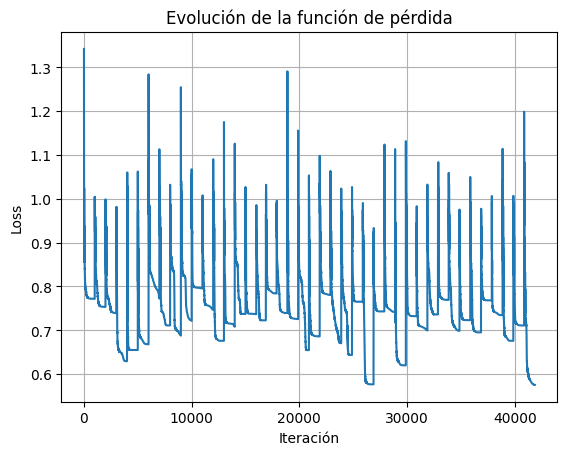

In [12]:
weight_params = modelo["weight_params"]
n_qubits = modelo["n_qubits"]
dim_target = modelo["dim_target"]
ansatz = modelo["ansatz"]
observable = modelo["observable"]
objective_func_vals = modelo["objective_func_vals"]
batch_size = modelo["batch_size"]
num_epochs = modelo["num_epochs"]

print("Qubits:", n_qubits)
print("Dimensión objetivo:", dim_target)
print("Cantidad de pesos entrenados:", len(weight_params))
print("Batch size:", batch_size)
print("Epochs:", num_epochs)
print("Observable:", observable)
import matplotlib.pyplot as plt

plt.plot(objective_func_vals)
plt.xlabel("Iteración")
plt.ylabel("Loss")
plt.title("Evolución de la función de pérdida")
plt.grid()
plt.show()

In [13]:
import joblib
import os

ruta_modelos = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"
nombre_modelo = "modelo_cuanticoC_bloque_entrega6.pkl"

ruta_modelo = os.path.join(ruta_modelos, nombre_modelo)

modelo = joblib.load(ruta_modelo)

print(type(modelo))
nombre_modelo = "modelo_cuanticoC1_bloque_entrega6.pkl"

<class 'dict'>


Qubits: 7
Dimensión objetivo: 128
Cantidad de pesos entrenados: 28
Batch size: 50
Epochs: 1
Observable: SparsePauliOp(['IIIIIIZ'],
              coeffs=[1.+0.j])


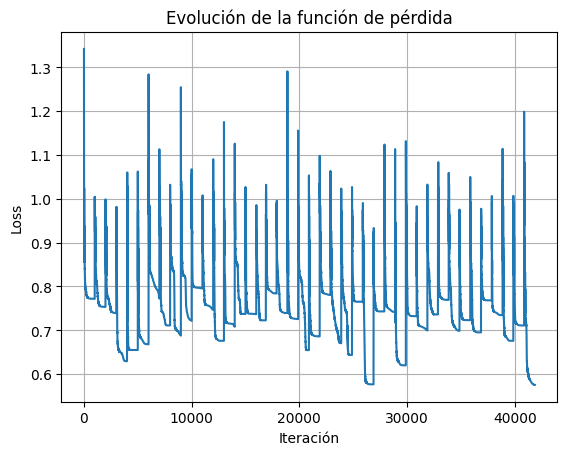

In [14]:
weight_params = modelo["weight_params"]
n_qubits = modelo["n_qubits"]
dim_target = modelo["dim_target"]
ansatz = modelo["ansatz"]
observable = modelo["observable"]
objective_func_vals = modelo["objective_func_vals"]
batch_size = modelo["batch_size"]
num_epochs = modelo["num_epochs"]

print("Qubits:", n_qubits)
print("Dimensión objetivo:", dim_target)
print("Cantidad de pesos entrenados:", len(weight_params))
print("Batch size:", batch_size)
print("Epochs:", num_epochs)
print("Observable:", observable)
import matplotlib.pyplot as plt

plt.plot(objective_func_vals)
plt.xlabel("Iteración")
plt.ylabel("Loss")
plt.title("Evolución de la función de pérdida")
plt.grid()
plt.show()

In [72]:
weight_params = modelo["weight_params"]
n_qubits = modelo["n_qubits"]
dim_target = modelo["dim_target"]
ansatz = modelo["ansatz"]
observable = modelo["observable"]
objective_func_vals = modelo["objective_func_vals"]

print("Qubits:", n_qubits)
print("Dimensión objetivo:", dim_target)
print("Pesos:", len(weight_params))
print("Ansatz:", ansatz)
print("Observable:", observable)

Qubits: 7
Dimensión objetivo: 128
Pesos: 28
Ansatz:      »
q_0: »
     »
q_1: »
     »
q_2: »
     »
q_3: »
     »
q_4: »
     »
q_5: »
     »
q_6: »
     »
«     ┌────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐
«q_0: ┤0                                                                                                                                                                               ├
«     │                                                                                                                                                                                │
«q_1: ┤1                                                                                                                                                                               ├
«     │                                                                                                

## Modelos con codificacion de amplitud

In [ ]:
def load_data(data_path: str) -> Tuple[pd.DataFrame, str]:
    """Load data from pickle or parquet format."""
    if data_path.endswith(".pkl") or data_path.endswith(".pickle"):
        return pd.read_pickle(data_path), "PICKLE"
    
def process_embeddings(df: pd.DataFrame, file_format: str) -> pd.DataFrame:
    if "embedding" not in df.columns:
        raise ValueError("Column 'embedding' not found in the dataframe.")

    if file_format in ("PICKLE", "PARQUET"):
        df["emb_array"] = df["embedding"].apply(lambda x: np.array(x, dtype=np.float32))

    return df

def get_insurance_column(df: pd.DataFrame) -> str:
    for col in ["new_insurance_type", "insurance", "insurance_type"]:
        if col in df.columns:
            return col
    raise ValueError("No insurance column found. Expected one of: new_insurance_type, insurance, insurance_type")
def data_prepare_cv(n_qubits, X_train, X_other):
    """
    Escala los datos y aplica PCA para reducir la dimensionalidad al número de qubits.
    
    El ajuste (fit) se hace SOLO con X_train para evitar fuga de información.
    Luego se transforma tanto X_train como el otro conjunto (validación o test).
    
    Parámetros
    ----------
    n_qubits : int
        Número de componentes principales (dimensión final para el modelo cuántico)
    X_train : np.ndarray
        Datos de entrenamiento
    X_other : np.ndarray
        Datos de validación o prueba

    Retorna
    -------
    X_train_pca : np.ndarray
        Datos de entrenamiento escalados y reducidos
    X_other_pca : np.ndarray
        Datos del otro conjunto transformados con el mismo escalador y PCA
    """

    #Escalado
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_other_scaled = scaler.transform(X_other)

    # Reducción de dimensionalidad con PCA al número de qubits
    #pca = PCA(n_components=n_qubits)
    #X_train_pca = pca.fit_transform(X_train_scaled)#Aprende usando solo los datos de entrenamiento
    #X_other_pca = pca.transform(X_other_scaled) #Aquí solo se aplica el mismo PCA aprendido con entrenamiento.

    #return X_train_pca, X_other_pca

def amplitude_normalization(data: np.array, target_dim) -> np.array:
    # Normalizar cada fila del dataset para que su "largo" sea 1
    # keepdims=True es vital para que pueda dividir correctamente l a matriz
    normas = np.linalg.norm(data, axis=1, keepdims=True)
    print(normas.max())
    # Dividimos cada dato por la norma de su fila
    dataset_normalizado = data / normas
    #dataset_normalizado=[matriz[i]/np.sqrt(np.sum(matriz[i]**2)) for i in range(matriz.shape[0])]
    #rellenar con ceros (Padding)
    # Crea una matriz de ceros del tamaño objetivo
    padded = np.zeros((len(dataset_normalizado), target_dim))
    # Copia los datos originales
    padded[:, :dataset_normalizado.shape[1]] = dataset_normalizado
    return padded

Shape original: (7996, 94)
maximo: 247.0  minimo: 0.0


In [62]:
X_p=np.abs(X)
print(X_p.max(), "   ", X_p.min())
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(X)

247.0     0.0


In [63]:
def pad_to_power_of_two(X, n_qubits):
    target_dim = 2**n_qubits
    padded = np.zeros((X.shape[0], target_dim), dtype=np.float32)
    padded[:, :X.shape[1]] = X
    return padded

X = pad_to_power_of_two(X, n_qubits)

In [64]:
X = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-10)

In [65]:
X_p=np.abs(X)
print(X_p.max(), "   ", X_p.min())

0.9982809     0.0


In [66]:
pca_features=0 #poner cero si no se quiere realizar PCA
# Create indices for tracking samples

indices = np.arange(len(X))

# Split: 80% train, 20% temp
X_train, X_temp, y_train, y_temp, idx_train, idx_temp = train_test_split(
    X, y, indices, test_size=0.2, stratify=y, random_state=seed
)

# Split temp: 50% val, 50% test (10% each of original)
X_val, X_test, y_val, y_test, idx_val, idx_test = train_test_split(
    X_temp, y_temp, idx_temp, test_size=0.5, stratify=y_temp, random_state=seed
)
# Apply PCA and scaling
if pca_features>1:
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    X_val_scaled = scaler.transform(X_val)
    if len(X_rest)>0:
        X_rest_scaled = scaler.transform(X_rest)

    pca = PCA(n_components=pca_features)

    X_train = pca.fit_transform(X_train_scaled)#Aprende usando solo los datos de entrenamiento
    X_test = pca.transform(X_test_scaled)
    X_val = pca.transform(X_val_scaled)
    if len(X_rest)>0:
        X_rest = pca.transform(X_rest_scaled)

In [67]:
num_features = X_train.shape[1]
n_qubits = int(np.ceil(np.log2(num_features)))
dim_target = 2**n_qubits

print(f"Features: {num_features} -> Qubits necesarios: {n_qubits}")

X_train = amplitude_normalization(X_train, dim_target)
X_val   = amplitude_normalization(X_val, dim_target)
X_test  = amplitude_normalization(X_test, dim_target)

Features: 128 -> Qubits necesarios: 7
1.0000001
1.0000001
1.0000001


C:\Users\javie\AppData\Local\Temp\ipykernel_19100\2847394999.py:1: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=n_qubits,reps=3,entanglement="circular")


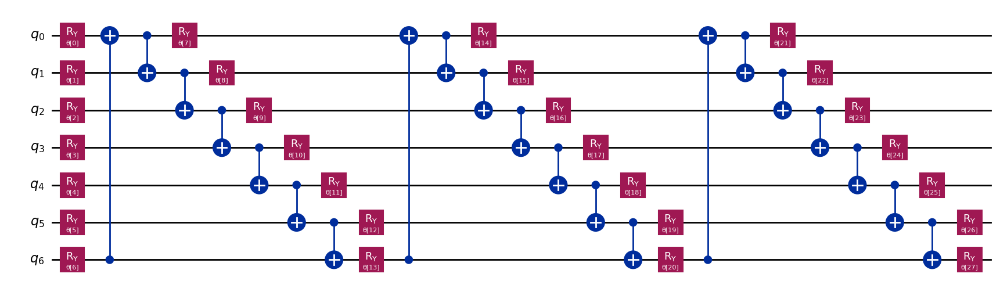

In [ ]:
ansatz = RealAmplitudes(num_qubits=n_qubits,reps=1,entanglement="linearr")
#ansatz = EfficientSU2(num_qubits=n_qubits, reps=1, entanglement='circular')
#ansatz = ZFeatureMap(feature_dimension=n_qubits, reps=1)
ansatz.decompose().draw('mpl')

In [69]:
#observable = SparsePauliOp.from_list([("Z" * (n_qubits), 1)])
observable = SparsePauliOp.from_list([("I" * (n_qubits - 1) + "Z", 1)])

In [70]:
# Esta versión de forward esta optimizada
def forward(
    input_data: np.ndarray,
    weight_params: np.ndarray,
    estimator,
    observable,
) -> np.ndarray:
    """
    Forward pass para amplitude encoding usando Initialize.
    Cada muestra se carga como estado cuántico.
    """

    predictions = []
    pubs = []

    for sample in input_data:
        amplitudes = sample / np.linalg.norm(sample)
        qc = QuantumCircuit(n_qubits)

        qc.initialize(amplitudes, range(n_qubits))
        qc.compose(ansatz, inplace=True)
        pubs.append((qc, observable, weight_params))
    job = estimator.run(pubs)
    result = job.result()
    predictions = [res.data.evs for res in result]

    return np.array(predictions).reshape(-1)
def mse_loss_weights(weight_params):
    preds = forward(input_params, weight_params, estimator, observable)

    preds = preds.reshape(-1)
    target_vec = np.array(target).reshape(-1)

    loss = np.mean((preds - target_vec) ** 2)
    print("predicciones: ",preds[0:50])
    
    objective_func_vals.append(float(loss))
    
    global iter
    
    
    #if iter % 50 == 0:
    if iter % 1 == 0:
        print(f"Iteración {iter} | Loss = {loss:.6f}")

    iter += 1


    return float(loss)


In [74]:
observables = observable
# input_params = train_images_batch
# target = train_labels_batch
objective_func_vals = []
iter = 0
batch_size =50  # puede ser menor a esto
num_epochs = 1
num_samples = len(X_train)

estimator = Estimator() 

print(num_samples)

# Random initial weights for the ansatz
np.random.seed(42)
#weight_params = np.random.rand(len(ansatz.parameters)) * 2 * np.pi
weight_params = np.random.uniform(-0.15, 0.15, len(ansatz.parameters))
print(weight_params)

for epoch in range(num_epochs):
    for i in range((num_samples - 1) // batch_size + 1):
        print(f"Epoch: {epoch}, batch: {i}")
        start_i = i * batch_size
        end_i = start_i + batch_size
        X_train_batch = np.array(X_train[start_i:end_i])
        y_train_batch = np.array(y_train[start_i:end_i])
        input_params = X_train_batch 
        target = y_train_batch
        iter = 0
        res = minimize(
            mse_loss_weights, weight_params, method="cobyla", options={"maxiter": 800}
        )
        weight_params = res["x"]

6396
[-0.03763796  0.13521429  0.06959818  0.02959755 -0.10319441 -0.10320164
 -0.13257492  0.10985284  0.0303345   0.06242177 -0.14382465  0.14097296
  0.09973279 -0.08629827 -0.09545251 -0.09497865 -0.05872733  0.00742693
 -0.02041649 -0.06263126  0.03355587 -0.10815184 -0.06235661 -0.04009145
 -0.013179    0.08555279 -0.09009787  0.00427033]
Epoch: 0, batch: 0
predicciones:  [ 0.48722682  0.81552111 -0.51145642  0.2928188  -0.50732708  0.62522197
  0.49363105  0.7212375  -0.73717029 -0.07172772 -0.50979278  0.31090181
  0.78672443 -0.40806929  0.02108034  0.13248757  0.31031966  0.2196022
 -0.65718272  0.68765465  0.82044354  0.01661704  0.45580606 -0.27236064
  0.87443705  0.28803897  0.33785751  0.27777986  0.70344612  0.19311631
 -0.85049512  0.57725628  0.79536981  0.56418913  0.88131619 -0.56053834
 -0.45239352  0.83514908  0.31871585  0.10209399  0.9333104   0.89760973
  0.34142773 -0.00769045  0.13218371 -0.51203325  0.04687227  0.51142709
  0.14866919 -0.6833667 ]
Iteración 

KeyboardInterrupt: 

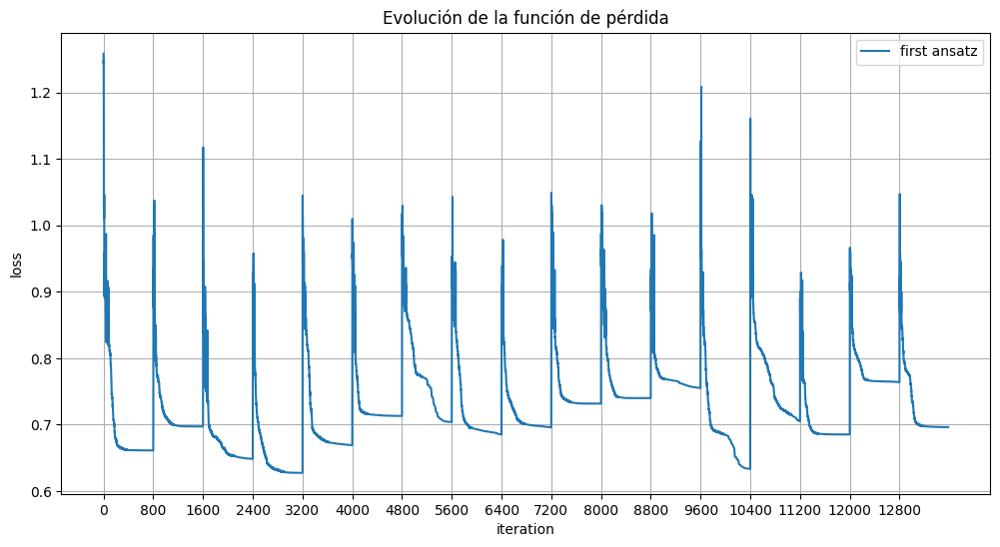

In [82]:
import matplotlib.pyplot as plt
import numpy as np

obj_func_vals_first = objective_func_vals

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_first, label="first ansatz")

plt.xlabel("iteration")
plt.ylabel("loss")
plt.title("Evolución de la función de pérdida")

paso = 800  # puedes cambiarlo a 5, 20, 25, etc.

plt.xticks(
    np.arange(0, len(obj_func_vals_first), paso)
)

plt.grid(True)
plt.legend()
plt.show()

#Creacion de un nuevo modelo

In [98]:
from qiskit import QuantumCircuit
import numpy as np

def forward(input_data, weight_params, estimator, observable, ansatz, n_qubits):
    pubs = []

    for sample in input_data:
        # Pasar a float64 para evitar errores de precisión
        amplitudes = np.asarray(sample, dtype=np.float64)

        # Normalizar justo antes de initialize
        norma = np.linalg.norm(amplitudes)

        if norma == 0:
            raise ValueError("Hay una muestra con norma cero. No se puede usar amplitude encoding.")

        amplitudes = amplitudes / norma

        # Corrección extra por redondeo numérico
        amplitudes = amplitudes / np.sqrt(np.sum(np.abs(amplitudes) ** 2))

        qc = QuantumCircuit(n_qubits)

        # normalize=True hace que Qiskit también normalice internamente
        qc.initialize(amplitudes, range(n_qubits), normalize=True)

        qc.compose(ansatz, inplace=True)

        pubs.append((qc, observable, weight_params))

    job = estimator.run(pubs)
    result = job.result()

    predictions = [res.data.evs for res in result]

    return np.array(predictions).reshape(-1)

In [94]:
def mse_loss_weights(weight_params, X_batch, y_batch):
    preds = forward(
        X_batch,
        weight_params,
        estimator,
        observable,
        ansatz,
        n_qubits
    )

    preds = preds.reshape(-1)
    target_vec = np.array(y_batch).reshape(-1)

    n_total = len(target_vec)
    n_FM = np.sum(target_vec == 1)
    n_AFM = np.sum(target_vec == -1)

    w_FM = n_total / (2 * n_FM) if n_FM > 0 else 0
    w_AFM = n_total / (2 * n_AFM) if n_AFM > 0 else 0

    weights = np.where(target_vec == 1, w_FM, w_AFM)

    loss = np.mean(weights * (preds - target_vec) ** 2)

    objective_func_vals.append(float(loss))

    return float(loss)

In [101]:
from scipy.optimize import minimize
import numpy as np

objective_func_vals = []
loss_por_batch = []

batch_size = 100
num_epochs = 1
maxiter_por_batch = 300

num_samples = len(X_train)

estimator = Estimator()

np.random.seed(42)
weight_params = np.random.uniform(
    -0.15,
    0.15,
    len(ansatz.parameters)
)

print("Número de muestras:", num_samples)
print("Número de parámetros:", len(weight_params))

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")

    indices = np.random.permutation(num_samples)

    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for i in range(0, num_samples, batch_size):

        X_train_batch = X_train_shuffled[i:i + batch_size]
        y_train_batch = y_train_shuffled[i:i + batch_size]

        print(f"Batch {i // batch_size + 1}")

        res = minimize(
            mse_loss_weights,
            weight_params,
            args=(X_train_batch, y_train_batch),
            method="COBYLA",
            options={"maxiter": maxiter_por_batch}
        )

        weight_params = res.xx  x
        loss_por_batch.append(res.fun)

        print(f"Loss batch: {res.fun:.6f}")

Número de muestras: 6396
Número de parámetros: 28

Epoch 1/1
Batch 1
Loss batch: 0.776347
Batch 2
Loss batch: 0.756829
Batch 3
Loss batch: 0.751498
Batch 4
Loss batch: 0.767524
Batch 5
Loss batch: 0.831701
Batch 6
Loss batch: 0.828085
Batch 7
Loss batch: 0.780195
Batch 8
Loss batch: 0.836853
Batch 9
Loss batch: 0.773564
Batch 10
Loss batch: 0.727365
Batch 11
Loss batch: 0.742611
Batch 12
Loss batch: 0.813520
Batch 13
Loss batch: 0.792769
Batch 14
Loss batch: 0.765881
Batch 15
Loss batch: 0.799325
Batch 16
Loss batch: 0.767510
Batch 17
Loss batch: 0.741932
Batch 18
Loss batch: 0.710881
Batch 19
Loss batch: 0.795362
Batch 20
Loss batch: 0.766974
Batch 21
Loss batch: 0.771999
Batch 22
Loss batch: 0.841478
Batch 23
Loss batch: 0.707437
Batch 24
Loss batch: 0.814511
Batch 25
Loss batch: 0.836896
Batch 26
Loss batch: 0.814097
Batch 27
Loss batch: 0.805294
Batch 28
Loss batch: 0.836125
Batch 29
Loss batch: 0.837009
Batch 30
Loss batch: 0.802402
Batch 31
Loss batch: 0.752906
Batch 32
Loss batc

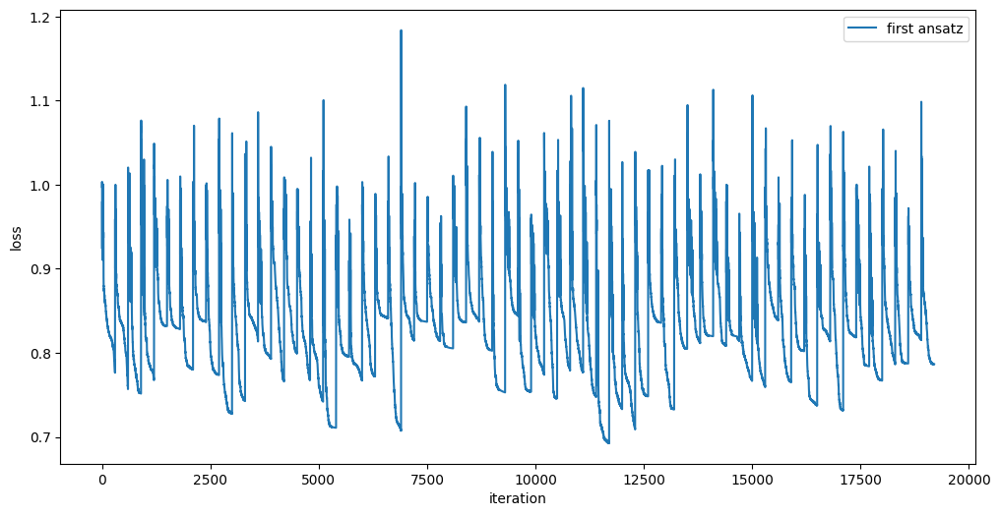

In [103]:
obj_func_vals_first = objective_func_vals
# import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(obj_func_vals_first, label="first ansatz")
plt.xlabel("iteration")
plt.ylabel("loss")
plt.legend()
plt.show()

In [107]:
def predecir_modelo_cuantico(X_data, batch_size_pred=100):
    y_pred_continuo = []

    for i in range(0, len(X_data), batch_size_pred):
        X_batch = X_data[i:i + batch_size_pred]

        preds = forward(
            X_batch,
            weight_params,
            estimator,
            observable,
            ansatz,
            n_qubits
        )

        preds = np.array(preds).reshape(-1)
        y_pred_continuo.extend(preds)

    y_pred_continuo = np.array(y_pred_continuo)

    # Convertir salida continua a clases:
    # Si pred >= 0  → FM  =  1
    # Si pred < 0   → AFM = -1
    y_pred_clases = np.where(y_pred_continuo >= 0.1,-1)

    return y_pred_continuo, y_pred_clases

Accuracy: 0.55625

Classification Report:

              precision    recall  f1-score   support

         AFM       0.37      0.52      0.43       259
          FM       0.71      0.57      0.64       541

    accuracy                           0.56       800
   macro avg       0.54      0.55      0.53       800
weighted avg       0.60      0.56      0.57       800



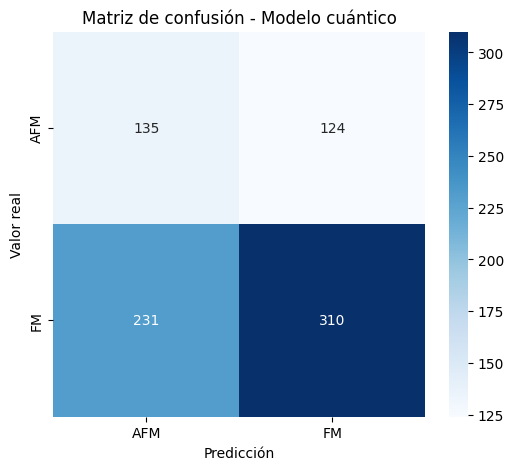


Ejemplos de predicción:

Real: 1 | Salida modelo: -0.1816 | Predicción: -1
Real: -1 | Salida modelo: 0.3768 | Predicción: 1
Real: 1 | Salida modelo: 0.0908 | Predicción: 1
Real: -1 | Salida modelo: 0.2866 | Predicción: 1
Real: -1 | Salida modelo: 0.1246 | Predicción: 1
Real: 1 | Salida modelo: -0.0210 | Predicción: -1
Real: 1 | Salida modelo: 0.0014 | Predicción: 1
Real: 1 | Salida modelo: -0.0718 | Predicción: -1
Real: 1 | Salida modelo: 0.3912 | Predicción: 1
Real: -1 | Salida modelo: 0.2098 | Predicción: 1


In [112]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

def predecir_modelo_cuantico(X_data, batch_size_pred=100):
    y_pred_continuo = []

    for i in range(0, len(X_data), batch_size_pred):
        X_batch = X_data[i:i + batch_size_pred]

        preds = forward(
            X_batch,
            weight_params,
            estimator,
            observable,
            ansatz,
            n_qubits
        )

        preds = np.array(preds).reshape(-1)
        y_pred_continuo.extend(preds)

    y_pred_continuo = np.array(y_pred_continuo)

    y_pred_clases = np.where(y_pred_continuo >= 0, 1, -1)

    return y_pred_continuo, y_pred_clases


# Evaluar en test
y_pred_continuo, y_pred = predecir_modelo_cuantico(X_test)

y_true = np.array(y_test).reshape(-1)

# Accuracy
print("Accuracy:", accuracy_score(y_true, y_pred))

# Classification report
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"]
))

# Matriz de confusión
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[-1, 1]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["AFM", "FM"],
    yticklabels=["AFM", "FM"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Modelo cuántico")
plt.show()

# Ver algunas predicciones
print("\nEjemplos de predicción:\n")
for i in range(10):
    print(
        f"Real: {y_true[i]} | "
        f"Salida modelo: {y_pred_continuo[i]:.4f} | "
        f"Predicción: {y_pred[i]}"
    )

In [113]:
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix, accuracy_score
import numpy as np

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_true, y_pred))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"]
))

print("\nDistribución real:")
print("AFM reales:", np.sum(y_true == -1))
print("FM reales:", np.sum(y_true == 1))

print("\nDistribución predicha:")
print("AFM predichos:", np.sum(y_pred == -1))
print("FM predichos:", np.sum(y_pred == 1))

Accuracy: 0.55625
Balanced Accuracy: 0.5471242301186848

Classification Report:

              precision    recall  f1-score   support

         AFM       0.37      0.52      0.43       259
          FM       0.71      0.57      0.64       541

    accuracy                           0.56       800
   macro avg       0.54      0.55      0.53       800
weighted avg       0.60      0.56      0.57       800


Distribución real:
AFM reales: 259
FM reales: 541

Distribución predicha:
AFM predichos: 366
FM predichos: 434


In [116]:
from sklearn.metrics import accuracy_score, classification_report

# Baseline: predecir siempre la clase mayoritaria, que en tu caso parece ser FM = 1
y_baseline = np.ones_like(y_true)

print("Accuracy baseline todo FM:", accuracy_score(y_true, y_baseline))

print("\nClassification Report baseline:\n")
print(classification_report(
    y_true,
    y_baseline,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

Accuracy baseline todo FM: 0.67625

Classification Report baseline:

              precision    recall  f1-score   support

         AFM       0.00      0.00      0.00       259
          FM       0.68      1.00      0.81       541

    accuracy                           0.68       800
   macro avg       0.34      0.50      0.40       800
weighted avg       0.46      0.68      0.55       800



El modelo cuántico todavía no es competitivo, porque una predicción simple basada en la clase mayoritaria obtiene mejor accuracy.

## Preparamos un nuevo modelo

In [1]:
# --- Librerías Estándar ---
import copy
from typing import Tuple

# --- Manipulación de Datos y Matemáticas ---
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# --- Visualización ---
import matplotlib
import matplotlib.pyplot as plt


# --- Scikit-Learn (Machine Learning Clásico) ---
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.metrics.pairwise import linear_kernel, polynomial_kernel, rbf_kernel

# --- Qiskit (Core y Circuitos) ---
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (
    EfficientSU2, Initialize, PauliFeatureMap, RealAmplitudes, 
    StatePreparation, ZFeatureMap, ZZFeatureMap, z_feature_map, zz_feature_map # Nota abajo sobre minúsculas
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import SparsePauliOp
from qiskit.quantum_info.operators.base_operator import BaseOperator

# --- Qiskit (Primitivas y Estimadores) ---
from qiskit.primitives import BaseEstimatorV2
from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit_aer.primitives import Estimator as AerEstimator
# Nota: Antes tenías 'as Estimator', puedes agregarlo si prefieres usar ese alias.

# --- Qiskit Machine Learning y Algoritmos ---
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_algorithms.optimizers import SPSA
from sklearn.preprocessing import MinMaxScaler
from qiskit_aer import AerSimulator
import seaborn as sns
import matplotlib.pyplot as plt
import math
from collections import Counter
ruta1 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_1.csv"  
ruta2 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_2.csv"
ruta3 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_3.csv"
ruta4 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_4.csv"
dfC1 = pd.read_csv(ruta1)
dfC2 = pd.read_csv(ruta2)
dfC3 = pd.read_csv(ruta3)
dfC4 = pd.read_csv(ruta4)
df = pd.concat([dfC1, dfC2, dfC3, dfC4], ignore_index=True)
# Ver distribución original
print("Distribución original:")
print(df["magnetic_label"].value_counts())





Distribución original:
magnetic_label
FM     5412
AFM    2584
Name: count, dtype: int64


In [2]:
# ================================
# 1. Preparación de datos
# ================================

# Nos quedamos solo con FM y AFM
df_modelo = df[df["magnetic_label"].isin(["FM", "AFM"])].copy()

print("Distribución usada:")
print(df_modelo["magnetic_label"].value_counts())

# Mapear etiquetas:
# FM  ->  1
# AFM -> -1
label_map = {
    "FM": 1,
    "AFM": -1
}

y = df_modelo["magnetic_label"].map(label_map).values.astype(int)

# Tomar solo columnas numéricas como features
X_df = df_modelo.drop(columns=["magnetic_label"])

# Eliminar columnas tipo índice si existen
columnas_indice = [col for col in X_df.columns if "unnamed" in col.lower()]
X_df = X_df.drop(columns=columnas_indice, errors="ignore")

# Seleccionar solo columnas numéricas
X_df = X_df.select_dtypes(include=[np.number])

# Reemplazar infinitos por NaN
X_df = X_df.replace([np.inf, -np.inf], np.nan)

# Rellenar NaN con la mediana de cada columna
X_df = X_df.fillna(X_df.median())

X = X_df.values.astype(np.float64)

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Número de features:", X.shape[1])

Distribución usada:
magnetic_label
FM     5412
AFM    2584
Name: count, dtype: int64
Forma de X: (7996, 94)
Forma de y: (7996,)
Número de features: 94


In [3]:
# ================================
# 2. Train / Validation / Test
# ================================

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.20,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape, Counter(y_train))
print("Val:", X_val.shape, Counter(y_val))
print("Test:", X_test.shape, Counter(y_test))

Train: (5116, 94) Counter({np.int64(1): 3463, np.int64(-1): 1653})
Val: (1280, 94) Counter({np.int64(1): 866, np.int64(-1): 414})
Test: (1600, 94) Counter({np.int64(1): 1083, np.int64(-1): 517})


In [4]:
# ================================
# 3. Escalamiento
# ================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train = np.asarray(X_train, dtype=np.float64)
X_val = np.asarray(X_val, dtype=np.float64)
X_test = np.asarray(X_test, dtype=np.float64)

y_train = np.asarray(y_train, dtype=int)
y_val = np.asarray(y_val, dtype=int)
y_test = np.asarray(y_test, dtype=int)

print("Escalamiento terminado.")

Escalamiento terminado.


In [5]:
# ================================
# 4. Número de qubits para amplitude encoding
# ================================

n_features = X_train.shape[1]

n_qubits = int(np.ceil(np.log2(n_features)))
target_dim = 2 ** n_qubits

print("Número de features:", n_features)
print("Número de qubits:", n_qubits)
print("Dimensión del estado cuántico:", target_dim)

Número de features: 94
Número de qubits: 7
Dimensión del estado cuántico: 128


Número de parámetros entrenables: 28


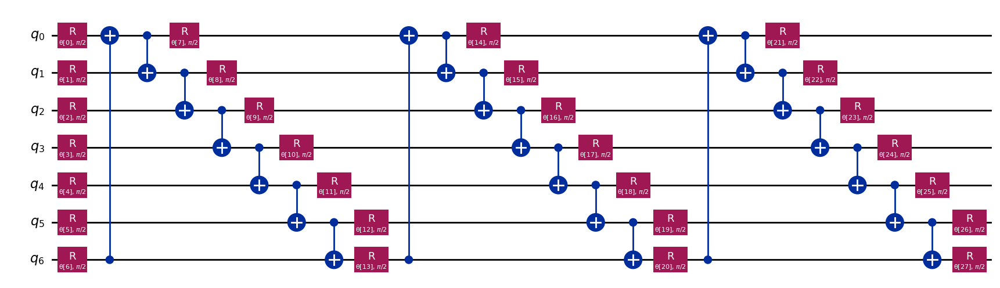

In [6]:
# ================================
# 5. Ansatz y observable
# ================================

from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

# Ansatz entrenable
ansatz = real_amplitudes(
    num_qubits=n_qubits,
    reps=3,
    entanglement="circular"
)

parametros_ansatz = list(ansatz.parameters)

print("Número de parámetros entrenables:", len(parametros_ansatz))

# Observable Z sobre el qubit 0
# La salida estará entre -1 y 1
observable = SparsePauliOp.from_list([
    ("I" * (n_qubits - 1) + "Z", 1.0)
])

estimator = StatevectorEstimator()

ansatz.decompose().draw("mpl")

In [7]:
# ================================
# 6. Normalización de amplitudes
# ================================

def normalizar_amplitudes(x, n_qubits):
    target_dim = 2 ** n_qubits

    x = np.asarray(x, dtype=np.float64).flatten()

    if len(x) < target_dim:
        x = np.pad(x, (0, target_dim - len(x)), mode="constant")

    elif len(x) > target_dim:
        raise ValueError(
            f"El vector tiene dimensión {len(x)}, pero con {n_qubits} qubits "
            f"solo se permiten {target_dim} amplitudes."
        )

    norm = np.linalg.norm(x)

    if norm == 0:
        x_norm = np.zeros(target_dim, dtype=np.float64)
        x_norm[0] = 1.0
        return x_norm

    x_norm = x / norm

    # Segunda normalización para evitar errores numéricos de Qiskit
    x_norm = x_norm / np.sqrt(np.sum(np.abs(x_norm) ** 2))

    return x_norm


In [8]:
# ================================
# 7. Forward del modelo cuántico
# ================================

def forward(X_batch, weight_params, estimator, observable):

    predicciones = []

    for x in X_batch:

        amplitudes = normalizar_amplitudes(x, n_qubits)

        qc = QuantumCircuit(n_qubits)

        # Amplitude encoding
        qc.initialize(amplitudes, range(n_qubits))

        # Agregar ansatz
        circuito = qc.compose(ansatz)

        # Asignar parámetros entrenables
        param_dict = dict(zip(parametros_ansatz, weight_params))
        circuito = circuito.assign_parameters(param_dict)

        # Evaluación con StatevectorEstimator
        resultado = estimator.run([
            (circuito, observable)
        ]).result()

        pred = resultado[0].data.evs
        pred = float(np.asarray(pred).reshape(-1)[0])

        predicciones.append(pred)

    return np.array(predicciones, dtype=np.float64)

In [9]:
# ================================
# Prueba rápida del forward
# ================================

np.random.seed(42)

weight_params_test = np.random.uniform(
    -0.15,
    0.15,
    len(parametros_ansatz)
)

preds_prueba = forward(
    X_train[:5],
    weight_params_test,
    estimator,
    observable
)

print("Predicciones de prueba:")
print(preds_prueba)

Predicciones de prueba:
[ 0.48884895  0.34436167 -0.72847892 -0.10031472  0.52634528]


In [10]:
# ================================
# 8. Loss ponderada
# ================================

objective_func_vals = []

def weighted_mse(preds, target_vec):

    preds = np.asarray(preds, dtype=np.float64).reshape(-1)
    target_vec = np.asarray(target_vec, dtype=int).reshape(-1)

    n_FM = np.sum(target_vec == 1)
    n_AFM = np.sum(target_vec == -1)

    w_FM = 1 / n_FM if n_FM > 0 else 0
    w_AFM = 1 / n_AFM if n_AFM > 0 else 0

    weights = np.where(target_vec == 1, w_FM, w_AFM)

    loss = np.sum(weights * (preds - target_vec) ** 2) / np.sum(weights)

    return float(loss)


def mse_loss_weights(weight_params, X_batch, y_batch):

    preds = forward(
        X_batch,
        weight_params,
        estimator,
        observable
    )

    loss = weighted_mse(preds, y_batch)

    objective_func_vals.append(float(loss))

    return float(loss)

In [11]:
# ================================
# 9. Evaluar loss en un conjunto fijo
# ================================

def predecir_continuo(X_data, weight_params, batch_size_pred=100):

    y_pred_continuo = []

    for i in range(0, len(X_data), batch_size_pred):

        X_batch = X_data[i:i + batch_size_pred]

        preds = forward(
            X_batch,
            weight_params,
            estimator,
            observable
        )

        y_pred_continuo.extend(preds)

    return np.array(y_pred_continuo, dtype=np.float64)


def evaluar_loss(weight_params, X_data, y_data, batch_size_eval=100):

    preds = predecir_continuo(
        X_data,
        weight_params,
        batch_size_pred=batch_size_eval
    )

    loss = weighted_mse(preds, y_data)

    return float(loss)

## Iniciamos el entrrenwamiento

In [18]:
# ================================
# 10. Entrenamiento
# ================================

objective_func_vals = []
loss_por_batch = []
val_loss_por_batch = []

batch_size = 100
num_epochs = 5
maxiter_por_batch = 1000

num_samples = len(X_train)

np.random.seed(42)

weight_params = np.random.uniform(
    -0.15,
    0.15,
    len(parametros_ansatz)
)

print("Número de muestras:", num_samples)
print("Número de parámetros:", len(weight_params))

# Early stopping
best_val_loss = np.inf
best_weights = weight_params.copy()

patience = 6
min_delta = 1e-4
contador_sin_mejora = 0

detener_entrenamiento = False

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")

    indices = np.random.permutation(num_samples)

    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for i in range(0, num_samples, batch_size):

        X_train_batch = X_train_shuffled[i:i + batch_size]
        y_train_batch = y_train_shuffled[i:i + batch_size]

        print(f"\nBatch {i // batch_size + 1}")

        res = minimize(
            mse_loss_weights,
            weight_params,
            args=(X_train_batch, y_train_batch),
            method="COBYLA",
            options={
                "maxiter": maxiter_por_batch,
                "rhobeg": 0.05,
                "tol": 1e-3
            }
        )

        weight_params = res.x
        loss_por_batch.append(res.fun)

        val_loss = evaluar_loss(
            weight_params,
            X_val,
            y_val,
            batch_size_eval=100
        )

        val_loss_por_batch.append(val_loss)

        print(f"Loss batch: {res.fun:.6f}")
        print(f"Loss validación: {val_loss:.6f}")

        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss
            best_weights = weight_params.copy()
            contador_sin_mejora = 0

            print("Mejoró validación. Pesos guardados.")

        else:

            contador_sin_mejora += 1

            print(f"No mejoró. Paciencia: {contador_sin_mejora}/{patience}")

        if contador_sin_mejora >= patience:

            print("\nEarly stopping activado.")
            detener_entrenamiento = True
            break

    if detener_entrenamiento:
        break


# Recuperar mejores pesos encontrados
weight_params = best_weights.copy()

print("\nEntrenamiento terminado.")
print("Mejor loss de validación:", best_val_loss)

Número de muestras: 5116
Número de parámetros: 28

Epoch 1/5

Batch 1
Loss batch: 0.769998
Loss validación: 0.957860
Mejoró validación. Pesos guardados.

Batch 2
Loss batch: 0.792892
Loss validación: 0.985763
No mejoró. Paciencia: 1/6

Batch 3
Loss batch: 0.779089
Loss validación: 0.960005
No mejoró. Paciencia: 2/6

Batch 4
Loss batch: 0.775106
Loss validación: 0.928502
Mejoró validación. Pesos guardados.

Batch 5
Loss batch: 0.769056
Loss validación: 1.074994
No mejoró. Paciencia: 1/6

Batch 6
Loss batch: 0.763220
Loss validación: 0.929217
No mejoró. Paciencia: 2/6

Batch 7
Loss batch: 0.807408
Loss validación: 0.938389
No mejoró. Paciencia: 3/6

Batch 8
Loss batch: 0.786926
Loss validación: 0.940153
No mejoró. Paciencia: 4/6

Batch 9
Loss batch: 0.780801
Loss validación: 0.961366
No mejoró. Paciencia: 5/6

Batch 10
Loss batch: 0.743561
Loss validación: 0.975675
No mejoró. Paciencia: 6/6

Early stopping activado.

Entrenamiento terminado.
Mejor loss de validación: 0.9285016565391881


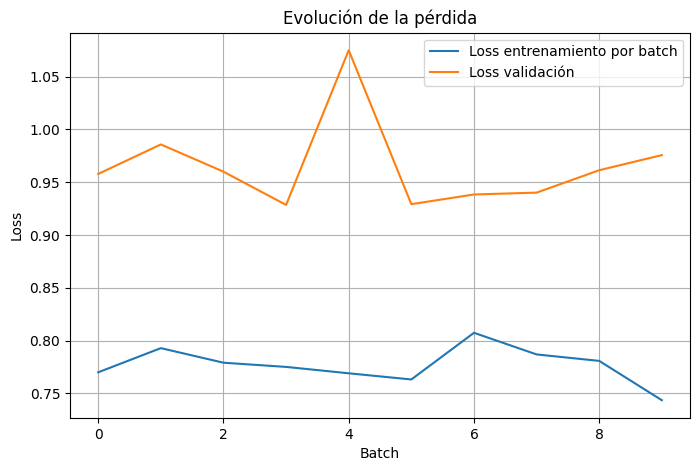

In [19]:
# ================================
# 11. Gráfica de pérdidas
# ================================

plt.figure(figsize=(8, 5))

plt.plot(loss_por_batch, label="Loss entrenamiento por batch")
plt.plot(val_loss_por_batch, label="Loss validación")

plt.xlabel("Batch")
plt.ylabel("Loss")
plt.title("Evolución de la pérdida")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# ================================
# 12. Evaluación final en test
# ================================

y_pred_continuo = predecir_continuo(
    X_test,
    weight_params,
    batch_size_pred=100
)

# Umbral natural del modelo:
# pred >= 0 -> FM
# pred <  0 -> AFM
y_pred = np.where(y_pred_continuo >= 0, 1, -1)

y_true = y_test.copy()

print("Mínimo pred:", np.min(y_pred_continuo))
print("Máximo pred:", np.max(y_pred_continuo))
print("Promedio pred:", np.mean(y_pred_continuo))
print("Desviación pred:", np.std(y_pred_continuo))

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("Precision macro:", precision_score(y_true, y_pred, average="macro"))
print("Recall macro:", recall_score(y_true, y_pred, average="macro"))
print("F1 macro:", f1_score(y_true, y_pred, average="macro"))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"]
))

Mínimo pred: -0.6144728080546142
Máximo pred: 0.6593309170084574
Promedio pred: 0.06527595748209192
Desviación pred: 0.2209401917113253

Accuracy: 0.643125
Precision macro: 0.6035230297652658
Recall macro: 0.6100210569179745
F1 macro: 0.6053521096340133

Classification Report:

              precision    recall  f1-score   support

         AFM       0.45      0.52      0.48       517
          FM       0.75      0.70      0.73      1083

    accuracy                           0.64      1600
   macro avg       0.60      0.61      0.61      1600
weighted avg       0.66      0.64      0.65      1600



In [23]:
# ================================
# 13. Baseline clase mayoritaria
# ================================

clase_mayoritaria = Counter(y_true).most_common(1)[0][0]

y_baseline = np.full_like(y_true, clase_mayoritaria)

print("Clase mayoritaria:", clase_mayoritaria)

print("\nAccuracy baseline:", accuracy_score(y_true, y_baseline))

print("\nClassification Report baseline:\n")
print(classification_report(
    y_true,
    y_baseline,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

Clase mayoritaria: 1

Accuracy baseline: 0.676875

Classification Report baseline:

              precision    recall  f1-score   support

         AFM       0.00      0.00      0.00       517
          FM       0.68      1.00      0.81      1083

    accuracy                           0.68      1600
   macro avg       0.34      0.50      0.40      1600
weighted avg       0.46      0.68      0.55      1600



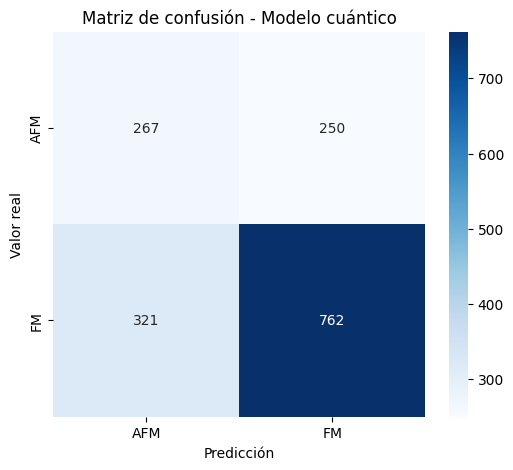

In [24]:
# ================================
# 14. Matriz de confusión
# ================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[-1, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["AFM", "FM"],
    yticklabels=["AFM", "FM"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Modelo cuántico")
plt.show()

Media AFM: -0.016187832501991344
Media FM: 0.10416495048465059
Std AFM: 0.203500078284832
Std FM: 0.2183296954685594
AFM correctamente negativos: 0.5164410058027079
FM correctamente positivos: 0.703601108033241


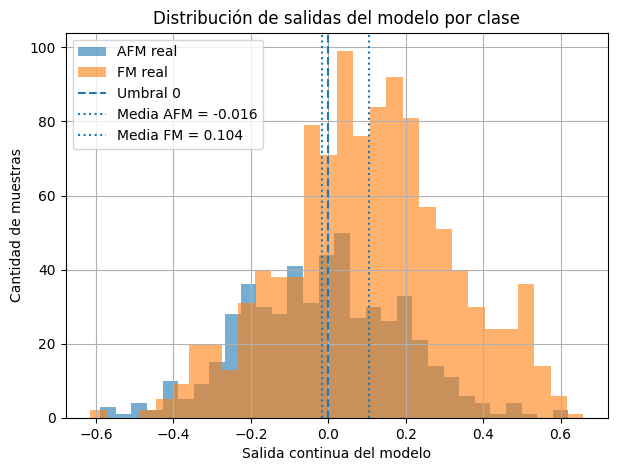

In [25]:
# ================================
# 15. Distribución de salidas por clase
# ================================

media_afm = np.mean(y_pred_continuo[y_true == -1])
media_fm = np.mean(y_pred_continuo[y_true == 1])

print("Media AFM:", media_afm)
print("Media FM:", media_fm)

print("Std AFM:", np.std(y_pred_continuo[y_true == -1]))
print("Std FM:", np.std(y_pred_continuo[y_true == 1]))

print("AFM correctamente negativos:",
      np.mean(y_pred_continuo[y_true == -1] < 0))

print("FM correctamente positivos:",
      np.mean(y_pred_continuo[y_true == 1] >= 0))

plt.figure(figsize=(7, 5))

plt.hist(
    y_pred_continuo[y_true == -1],
    bins=30,
    alpha=0.6,
    label="AFM real"
)

plt.hist(
    y_pred_continuo[y_true == 1],
    bins=30,
    alpha=0.6,
    label="FM real"
)

plt.axvline(0, linestyle="--", label="Umbral 0")
plt.axvline(media_afm, linestyle=":", label=f"Media AFM = {media_afm:.3f}")
plt.axvline(media_fm, linestyle=":", label=f"Media FM = {media_fm:.3f}")

plt.xlabel("Salida continua del modelo")
plt.ylabel("Cantidad de muestras")
plt.title("Distribución de salidas del modelo por clase")
plt.legend()
plt.grid(True)
plt.show()

In [26]:
weight_params = best_weights.copy()

In [27]:
# ============================================
# FASE 2: seguir entrenando desde best_weights
# ============================================

weight_params = best_weights.copy()

print("Loss validación antes de fase 2:")
print(evaluar_loss(weight_params, X_val, y_val, batch_size_eval=100))

# Reiniciar early stopping para la fase 2
best_val_loss = evaluar_loss(weight_params, X_val, y_val, batch_size_eval=100)
best_weights = weight_params.copy()

patience = 5
min_delta = 1e-4
contador_sin_mejora = 0
detener_entrenamiento = False

# Parámetros más suaves
batch_size = 100
num_epochs_fase2 = 5
maxiter_por_batch = 30

for epoch in range(num_epochs_fase2):

    print(f"\nFase 2 - Epoch {epoch + 1}/{num_epochs_fase2}")

    indices = np.random.permutation(num_samples)

    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for i in range(0, num_samples, batch_size):

        X_train_batch = X_train_shuffled[i:i + batch_size]
        y_train_batch = y_train_shuffled[i:i + batch_size]

        print(f"\nBatch {i // batch_size + 1}")

        res = minimize(
            mse_loss_weights,
            weight_params,
            args=(X_train_batch, y_train_batch),
            method="COBYLA",
            options={
                "maxiter": maxiter_por_batch,
                "rhobeg": 0.01,
                "tol": 1e-4
            }
        )

        weight_params = res.x
        loss_por_batch.append(res.fun)

        val_loss = evaluar_loss(
            weight_params,
            X_val,
            y_val,
            batch_size_eval=100
        )

        val_loss_por_batch.append(val_loss)

        print(f"Loss batch: {res.fun:.6f}")
        print(f"Loss validación: {val_loss:.6f}")

        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss
            best_weights = weight_params.copy()
            contador_sin_mejora = 0

            print("Mejoró validación. Pesos guardados.")

        else:

            contador_sin_mejora += 1

            print(f"No mejoró. Paciencia: {contador_sin_mejora}/{patience}")

        if contador_sin_mejora >= patience:

            print("\nEarly stopping activado en fase 2.")
            detener_entrenamiento = True
            break

    if detener_entrenamiento:
        break

# Recuperar mejores pesos de la fase 2
weight_params = best_weights.copy()

print("\nFase 2 terminada.")
print("Mejor loss validación fase 2:", best_val_loss)

Loss validación antes de fase 2:
0.9285016565391881

Fase 2 - Epoch 1/5

Batch 1
Loss batch: 0.997091
Loss validación: 0.926904
Mejoró validación. Pesos guardados.

Batch 2
Loss batch: 0.841533
Loss validación: 0.925650
Mejoró validación. Pesos guardados.

Batch 3
Loss batch: 0.968979
Loss validación: 0.924324
Mejoró validación. Pesos guardados.

Batch 4
Loss batch: 0.910576
Loss validación: 0.923337
Mejoró validación. Pesos guardados.

Batch 5
Loss batch: 0.904047
Loss validación: 0.921758
Mejoró validación. Pesos guardados.

Batch 6
Loss batch: 0.883588
Loss validación: 0.922123
No mejoró. Paciencia: 1/5

Batch 7
Loss batch: 0.923474
Loss validación: 0.921007
Mejoró validación. Pesos guardados.

Batch 8
Loss batch: 0.917653
Loss validación: 0.920071
Mejoró validación. Pesos guardados.

Batch 9
Loss batch: 0.870596
Loss validación: 0.918987
Mejoró validación. Pesos guardados.

Batch 10
Loss batch: 0.924648
Loss validación: 0.918242
Mejoró validación. Pesos guardados.

Batch 11
Loss ba

In [28]:
y_pred_continuo = predecir_continuo(
    X_test,
    weight_params,
    batch_size_pred=100
)

y_pred = np.where(y_pred_continuo >= 0, 1, -1)
y_true = y_test.copy()

print("Mínimo pred:", np.min(y_pred_continuo))
print("Máximo pred:", np.max(y_pred_continuo))
print("Promedio pred:", np.mean(y_pred_continuo))
print("Desviación pred:", np.std(y_pred_continuo))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"]
))

print("Accuracy:", accuracy_score(y_true, y_pred))
print("F1 macro:", f1_score(y_true, y_pred, average="macro"))

Mínimo pred: -0.5708616852711371
Máximo pred: 0.6461221805931558
Promedio pred: 0.08153776558865315
Desviación pred: 0.20247156061145613

Classification Report:

              precision    recall  f1-score   support

         AFM       0.45      0.52      0.48       517
          FM       0.75      0.70      0.73      1083

    accuracy                           0.64      1600
   macro avg       0.60      0.61      0.61      1600
weighted avg       0.66      0.64      0.65      1600

Accuracy: 0.6425
F1 macro: 0.6055002370791844


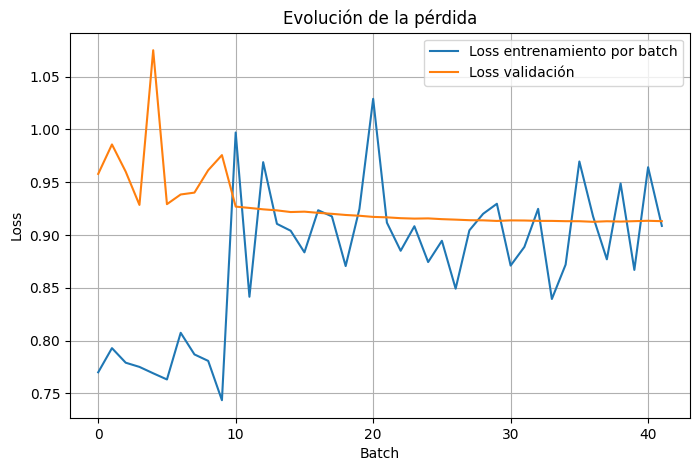

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(loss_por_batch, label="Loss entrenamiento por batch")
plt.plot(val_loss_por_batch, label="Loss validación")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.title("Evolución de la pérdida")s
plt.legend()
plt.grid(True)
plt.show()

Media AFM: -0.007562308205214139
Media FM: 0.12407214984666738
Std AFM: 0.1666777101155687
Std FM: 0.20421425977757449
AFM correctamente negativos: 0.5203094777562862
FM correctamente positivos: 0.7008310249307479


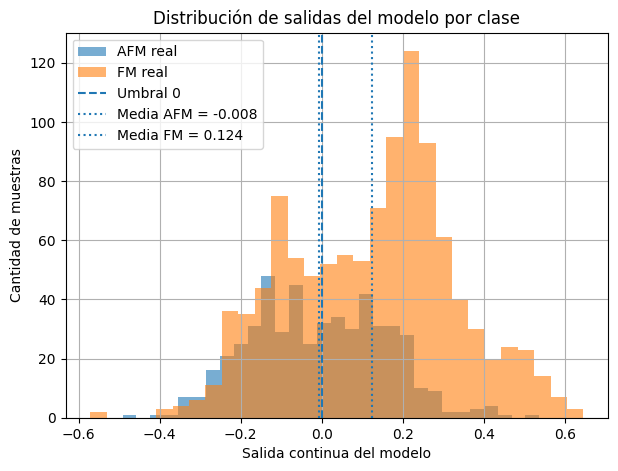

In [30]:
# ================================
# 15. Distribución de salidas por clase
# ================================

media_afm = np.mean(y_pred_continuo[y_true == -1])
media_fm = np.mean(y_pred_continuo[y_true == 1])

print("Media AFM:", media_afm)
print("Media FM:", media_fm)

print("Std AFM:", np.std(y_pred_continuo[y_true == -1]))
print("Std FM:", np.std(y_pred_continuo[y_true == 1]))

print("AFM correctamente negativos:",
      np.mean(y_pred_continuo[y_true == -1] < 0))

print("FM correctamente positivos:",
      np.mean(y_pred_continuo[y_true == 1] >= 0))

plt.figure(figsize=(7, 5))

plt.hist(
    y_pred_continuo[y_true == -1],
    bins=30,
    alpha=0.6,
    label="AFM real"
)

plt.hist(
    y_pred_continuo[y_true == 1],
    bins=30,
    alpha=0.6,
    label="FM real"
)

plt.axvline(0, linestyle="--", label="Umbral 0")
plt.axvline(media_afm, linestyle=":", label=f"Media AFM = {media_afm:.3f}")
plt.axvline(media_fm, linestyle=":", label=f"Media FM = {media_fm:.3f}")

plt.xlabel("Salida continua del modelo")
plt.ylabel("Cantidad de muestras")
plt.title("Distribución de salidas del modelo por clase")
plt.legend()
plt.grid(True)
plt.show()

In [33]:
from collections import Counter
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)
clase_mayoritaria = Counter(y_true).most_common(1)[0][0]
y_baseline = np.full_like(y_true, clase_mayoritaria)

print("Clase mayoritaria:", clase_mayoritaria)

print("Accuracy baseline:", accuracy_score(y_true, y_baseline))
print("Balanced Accuracy baseline:", balanced_accuracy_score(y_true, y_baseline))
print("F1 macro baseline:", f1_score(y_true, y_baseline, average="macro"))

print("\nReporte baseline:\n")
print(classification_report(
    y_true,
    y_baseline,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

Clase mayoritaria: 1
Accuracy baseline: 0.676875
Balanced Accuracy baseline: 0.5
F1 macro baseline: 0.4036526276556094

Reporte baseline:

              precision    recall  f1-score   support

         AFM       0.00      0.00      0.00       517
          FM       0.68      1.00      0.81      1083

    accuracy                           0.68      1600
   macro avg       0.34      0.50      0.40      1600
weighted avg       0.46      0.68      0.55      1600



In [38]:
# ================================
# Evaluación con los mejores pesos
# ================================

weight_params = best_weights.copy()

y_pred_continuo = predecir_continuo(
    X_test,
    weight_params,
    batch_size_pred=100
)

y_pred = np.where(y_pred_continuo >= 0, 1, -1)
y_true = y_test.copy()

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_true, y_pred))
print("F1 macro:", f1_score(y_true, y_pred, average="macro"))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"]
))

Accuracy: 0.6425
Balanced Accuracy: 0.6105702513435171
F1 macro: 0.6055002370791844

Classification Report:

              precision    recall  f1-score   support

         AFM       0.45      0.52      0.48       517
          FM       0.75      0.70      0.73      1083

    accuracy                           0.64      1600
   macro avg       0.60      0.61      0.61      1600
weighted avg       0.66      0.64      0.65      1600



In [39]:
# ================================
# Loss con margen para clasificación
# ================================

objective_func_vals = []

def weighted_margin_loss(preds, target_vec, margin=0.25):

    preds = np.asarray(preds, dtype=np.float64).reshape(-1)
    target_vec = np.asarray(target_vec, dtype=int).reshape(-1)

    n_FM = np.sum(target_vec == 1)
    n_AFM = np.sum(target_vec == -1)

    w_FM = 1 / n_FM if n_FM > 0 else 0
    w_AFM = 1 / n_AFM if n_AFM > 0 else 0

    weights = np.where(target_vec == 1, w_FM, w_AFM)

    # y * pred debe ser positivo si clasifica bien
    margen = target_vec * preds

    # Penaliza si no llega al margen deseado
    errores = np.maximum(0, margin - margen) ** 2

    loss = np.sum(weights * errores) / np.sum(weights)

    return float(loss)


def margin_loss_weights(weight_params, X_batch, y_batch):

    preds = forward(
        X_batch,
        weight_params,
        estimator,
        observable
    )

    loss = weighted_margin_loss(
        preds,
        y_batch,
        margin=0.25
    )

    objective_func_vals.append(float(loss))

    return float(loss)

In [41]:
def evaluar_margin_loss(weight_params, X_data, y_data, batch_size_eval=100):

    preds = predecir_continuo(
        X_data,
        weight_params,
        batch_size_pred=batch_size_eval
    )

    return weighted_margin_loss(
        preds,
        y_data,
        margin=0.25
    )

In [42]:
# ============================================
# FASE 3: entrenamiento con loss de margen
# ============================================

weight_params = best_weights.copy()

print("Margin loss validación antes de fase 3:")
print(evaluar_margin_loss(weight_params, X_val, y_val, batch_size_eval=100))

best_val_loss = evaluar_margin_loss(weight_params, X_val, y_val, batch_size_eval=100)
best_weights = weight_params.copy()

patience = 5
min_delta = 1e-4
contador_sin_mejora = 0
detener_entrenamiento = False

batch_size = 100
num_epochs_fase3 = 5
maxiter_por_batch = 30

loss_por_batch_margin = []
val_loss_por_batch_margin = []

for epoch in range(num_epochs_fase3):

    print(f"\nFase 3 - Epoch {epoch + 1}/{num_epochs_fase3}")

    indices = np.random.permutation(num_samples)

    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for i in range(0, num_samples, batch_size):

        X_train_batch = X_train_shuffled[i:i + batch_size]
        y_train_batch = y_train_shuffled[i:i + batch_size]

        print(f"\nBatch {i // batch_size + 1}")

        res = minimize(
            margin_loss_weights,
            weight_params,
            args=(X_train_batch, y_train_batch),
            method="COBYLA",
            options={
                "maxiter": maxiter_por_batch,
                "rhobeg": 0.01,
                "tol": 1e-4
            }
        )

        weight_params = res.x
        loss_por_batch_margin.append(res.fun)

        val_loss = evaluar_margin_loss(
            weight_params,
            X_val,
            y_val,
            batch_size_eval=100
        )

        val_loss_por_batch_margin.append(val_loss)

        print(f"Margin loss batch: {res.fun:.6f}")
        print(f"Margin loss validación: {val_loss:.6f}")

        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss
            best_weights = weight_params.copy()
            contador_sin_mejora = 0

            print("Mejoró validación. Pesos guardados.")

        else:

            contador_sin_mejora += 1

            print(f"No mejoró. Paciencia: {contador_sin_mejora}/{patience}")

        if contador_sin_mejora >= patience:

            print("\nEarly stopping activado en fase 3.")
            detener_entrenamiento = True
            break

    if detener_entrenamiento:
        break

weight_params = best_weights.copy()

print("\nFase 3 terminada.")
print("Mejor margin loss validación fase 3:", best_val_loss)

Margin loss validación antes de fase 3:
0.0711441923793904

Fase 3 - Epoch 1/5

Batch 1
Margin loss batch: 0.058598
Margin loss validación: 0.069796
Mejoró validación. Pesos guardados.

Batch 2
Margin loss batch: 0.044952
Margin loss validación: 0.068985
Mejoró validación. Pesos guardados.

Batch 3
Margin loss batch: 0.061909
Margin loss validación: 0.068032
Mejoró validación. Pesos guardados.

Batch 4
Margin loss batch: 0.064419
Margin loss validación: 0.067049
Mejoró validación. Pesos guardados.

Batch 5
Margin loss batch: 0.057487
Margin loss validación: 0.066917
Mejoró validación. Pesos guardados.

Batch 6
Margin loss batch: 0.054426
Margin loss validación: 0.066689
Mejoró validación. Pesos guardados.

Batch 7
Margin loss batch: 0.080349
Margin loss validación: 0.065908
Mejoró validación. Pesos guardados.

Batch 8
Margin loss batch: 0.067751
Margin loss validación: 0.065176
Mejoró validación. Pesos guardados.

Batch 9
Margin loss batch: 0.068701
Margin loss validación: 0.064624
Mej

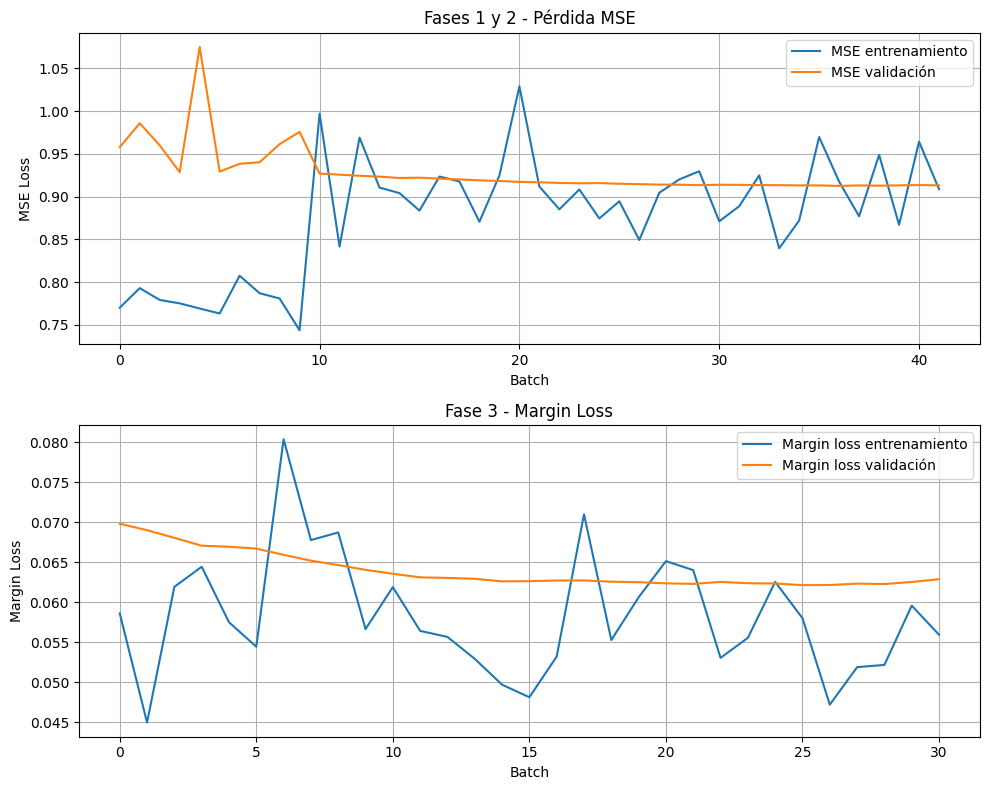

In [47]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# Gráfica de pérdidas durante las fases 1, 2 y 3
# =====================================================

# Fase 1 + Fase 2: MSE loss
mse_train = np.array(loss_por_batch)
mse_val = np.array(val_loss_por_batch)

# Fase 3: Margin loss
margin_train = np.array(loss_por_batch_margin)
margin_val = np.array(val_loss_por_batch_margin)

fig, axs = plt.subplots(2, 1, figsize=(10, 8), sharex=False)

# ================================
# Gráfica Fase 1 + Fase 2
# ================================

axs[0].plot(mse_train, label="MSE entrenamiento")
axs[0].plot(mse_val, label="MSE validación")

axs[0].set_title("Fases 1 y 2 - Pérdida MSE")
axs[0].set_xlabel("Batch")
axs[0].set_ylabel("MSE Loss")
axs[0].grid(True)
axs[0].legend()

# ================================
# Gráfica Fase 3
# ================================

axs[1].plot(margin_train, label="Margin loss entrenamiento")
axs[1].plot(margin_val, label="Margin loss validación")

axs[1].set_title("Fase 3 - Margin Loss")
axs[1].set_xlabel("Batch")
axs[1].set_ylabel("Margin Loss")
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

In [48]:
weight_params = best_weights.copy()

In [49]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ================================
# Predicciones finales en TEST
# ================================

y_pred_continuo = predecir_continuo(
    X_test,
    weight_params,
    batch_size_pred=100
)

# Umbral natural
# pred >= 0 -> FM
# pred <  0 -> AFM
y_pred = np.where(y_pred_continuo >= 0, 1, -1)

y_true = y_test.copy()

# ================================
# Métricas del modelo cuántico
# ================================

accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("===== MÉTRICAS MODELO CUÁNTICO =====")
print("Accuracy:", accuracy)
print("Balanced Accuracy:", balanced_acc)
print("Precision macro:", precision_macro)
print("Recall macro:", recall_macro)
print("F1 macro:", f1_macro)

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

===== MÉTRICAS MODELO CUÁNTICO =====
Accuracy: 0.63625
Balanced Accuracy: 0.6069643211153202
Precision macro: 0.5993619255712558
Recall macro: 0.6069643211153202
F1 macro: 0.6009297924423508

Classification Report:

              precision    recall  f1-score   support

         AFM       0.45      0.52      0.48       517
          FM       0.75      0.69      0.72      1083

    accuracy                           0.64      1600
   macro avg       0.60      0.61      0.60      1600
weighted avg       0.65      0.64      0.64      1600



In [50]:
# ================================
# Baseline clase mayoritaria
# ================================

clase_mayoritaria = Counter(y_true).most_common(1)[0][0]

y_baseline = np.full_like(y_true, clase_mayoritaria)

accuracy_base = accuracy_score(y_true, y_baseline)
balanced_acc_base = balanced_accuracy_score(y_true, y_baseline)
precision_macro_base = precision_score(y_true, y_baseline, average="macro", zero_division=0)
recall_macro_base = recall_score(y_true, y_baseline, average="macro", zero_division=0)
f1_macro_base = f1_score(y_true, y_baseline, average="macro", zero_division=0)

print("===== MÉTRICAS BASELINE =====")
print("Clase mayoritaria:", clase_mayoritaria)
print("Accuracy baseline:", accuracy_base)
print("Balanced Accuracy baseline:", balanced_acc_base)
print("Precision macro baseline:", precision_macro_base)
print("Recall macro baseline:", recall_macro_base)
print("F1 macro baseline:", f1_macro_base)

print("\nClassification Report baseline:\n")
print(classification_report(
    y_true,
    y_baseline,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

===== MÉTRICAS BASELINE =====
Clase mayoritaria: 1
Accuracy baseline: 0.676875
Balanced Accuracy baseline: 0.5
Precision macro baseline: 0.3384375
Recall macro baseline: 0.5
F1 macro baseline: 0.4036526276556094

Classification Report baseline:

              precision    recall  f1-score   support

         AFM       0.00      0.00      0.00       517
          FM       0.68      1.00      0.81      1083

    accuracy                           0.68      1600
   macro avg       0.34      0.50      0.40      1600
weighted avg       0.46      0.68      0.55      1600



In [51]:
# ================================
# Tabla comparativa
# ================================

tabla_metricas = pd.DataFrame({
    "Modelo": ["Baseline clase mayoritaria", "Modelo cuántico"],
    "Accuracy": [accuracy_base, accuracy],
    "Balanced Accuracy": [balanced_acc_base, balanced_acc],
    "Precision macro": [precision_macro_base, precision_macro],
    "Recall macro": [recall_macro_base, recall_macro],
    "F1 macro": [f1_macro_base, f1_macro]
})

display(tabla_metricas)

,Modelo,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro
0,Baseline clase mayoritaria,0.676875,0.500000,0.338438,0.500000,0.403653
1,Modelo cuántico,0.636250,0.606964,0.599362,0.606964,0.600930


<Figure size 1000x500 with 0 Axes>

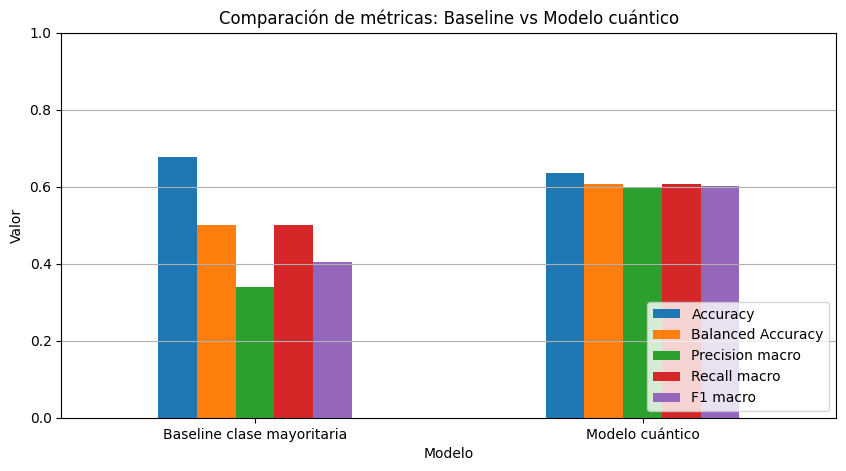

In [52]:
# ================================
# Gráfica de métricas
# ================================

metricas_plot = tabla_metricas.set_index("Modelo")

plt.figure(figsize=(10, 5))

metricas_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Comparación de métricas: Baseline vs Modelo cuántico")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

Media AFM: -0.00561207782229689
Media FM: 0.08282693316064182
Std AFM: 0.11702768305225854
Std FM: 0.16007168508276814
AFM correctamente negativos: 0.5241779497098646
FM correctamente positivos: 0.6897506925207756


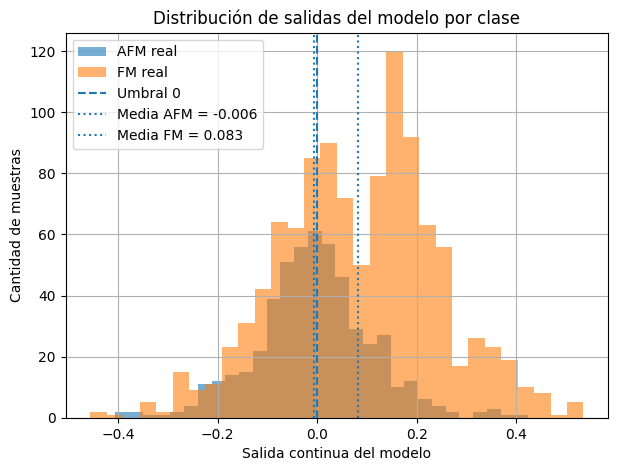

In [54]:
# ================================
# 15. Distribución de salidas por clase
# ================================

media_afm = np.mean(y_pred_continuo[y_true == -1])
media_fm = np.mean(y_pred_continuo[y_true == 1])

print("Media AFM:", media_afm)
print("Media FM:", media_fm)

print("Std AFM:", np.std(y_pred_continuo[y_true == -1]))
print("Std FM:", np.std(y_pred_continuo[y_true == 1]))

print("AFM correctamente negativos:",
      np.mean(y_pred_continuo[y_true == -1] < 0))

print("FM correctamente positivos:",
      np.mean(y_pred_continuo[y_true == 1] >= 0))

plt.figure(figsize=(7, 5))

plt.hist(
    y_pred_continuo[y_true == -1],
    bins=30,
    alpha=0.6,
    label="AFM real"
)

plt.hist(
    y_pred_continuo[y_true == 1],
    bins=30,
    alpha=0.6,
    label="FM real"
)

plt.axvline(0, linestyle="--", label="Umbral 0")
plt.axvline(media_afm, linestyle=":", label=f"Media AFM = {media_afm:.3f}")
plt.axvline(media_fm, linestyle=":", label=f"Media FM = {media_fm:.3f}")

plt.xlabel("Salida continua del modelo")
plt.ylabel("Cantidad de muestras")
plt.title("Distribución de salidas del modelo por clase")
plt.legend()
plt.grid(True)
plt.show()

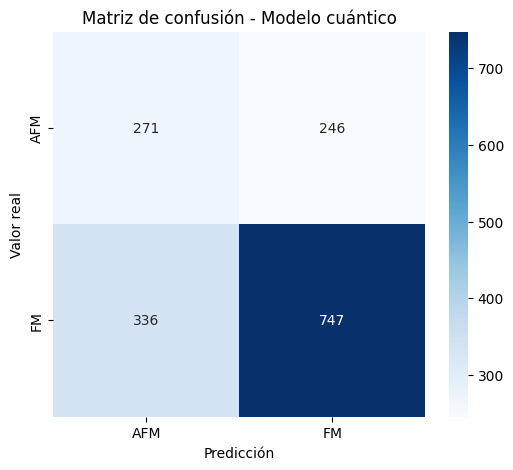

In [53]:
# ================================
# Matriz de confusión
# ================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[-1, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["AFM", "FM"],
    yticklabels=["AFM", "FM"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Modelo cuántico")
plt.show()

El modelo cuántico no supera a la baseline en accuracy global, pero sí la supera en métricas balanceadas. Esto indica que el clasificador dejó de comportarse como un predictor trivial de la clase mayoritaria y empezó a capturar información útil para distinguir ambas fases magnéticas, especialmente al mejorar la detección de la clase minoritaria AFM.

Guardamos el modelo

In [55]:
import os
import json
import pickle
import numpy as np
import pandas as pd
from qiskit import qpy

# ============================================
# Ruta donde se guardará el modelo
# ============================================

ruta_modelo = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6"

os.makedirs(ruta_modelo, exist_ok=True)

# ============================================
# 1. Guardar pesos entrenados
# ============================================

np.save(
    os.path.join(ruta_modelo, "pesos_modelo_cuantico.npy"),
    weight_params
)

# ============================================
# 2. Guardar scaler
# ============================================

with open(os.path.join(ruta_modelo, "scaler.pkl"), "wb") as f:
    pickle.dump(scaler, f)

# ============================================
# 3. Guardar ansatz cuántico
# ============================================

with open(os.path.join(ruta_modelo, "ansatz.qpy"), "wb") as f:
    qpy.dump(ansatz, f)

# ============================================
# 4. Guardar observable
# ============================================

with open(os.path.join(ruta_modelo, "observable.pkl"), "wb") as f:
    pickle.dump(observable, f)

# ============================================
# 5. Guardar columnas usadas como features
# ============================================

feature_columns = list(X_df.columns)

with open(os.path.join(ruta_modelo, "feature_columns.json"), "w") as f:
    json.dump(feature_columns, f, indent=4)

# ============================================
# 6. Guardar configuración del modelo
# ============================================

config_modelo = {
    "n_qubits": int(n_qubits),
    "target_dim": int(target_dim),
    "n_features": int(n_features),
    "num_parametros": int(len(weight_params)),
    "encoding": "amplitude_encoding",
    "ansatz": "real_amplitudes",
    "entanglement": "circular",
    "labels": {
        "AFM": -1,
        "FM": 1
    },
    "umbral_clasificacion": 0
}

with open(os.path.join(ruta_modelo, "config_modelo.json"), "w") as f:
    json.dump(config_modelo, f, indent=4)

# ============================================
# 7. Guardar pérdidas de entrenamiento
# ============================================

np.savez_compressed(
    os.path.join(ruta_modelo, "historial_perdidas.npz"),
    loss_por_batch=np.array(loss_por_batch),
    val_loss_por_batch=np.array(val_loss_por_batch),
    loss_por_batch_margin=np.array(loss_por_batch_margin),
    val_loss_por_batch_margin=np.array(val_loss_por_batch_margin)
)

# ============================================
# 8. Guardar métricas, si existe tabla_metricas
# ============================================

try:
    tabla_metricas.to_csv(
        os.path.join(ruta_modelo, "metricas_modelo.csv"),
        index=False
    )
except:
    print("No se encontró tabla_metricas. Se omite guardar métricas en CSV.")

# ============================================
# 9. Guardar predicciones finales
# ============================================

try:
    predicciones_df = pd.DataFrame({
        "y_true": y_true,
        "y_pred": y_pred,
        "y_pred_continuo": y_pred_continuo
    })

    predicciones_df.to_csv(
        os.path.join(ruta_modelo, "predicciones_test.csv"),
        index=False
    )
except:
    print("No se encontraron y_true, y_pred o y_pred_continuo. Se omite guardar predicciones.")

print("Modelo guardado correctamente en:")
print(ruta_modelo)

Modelo guardado correctamente en:
C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6


## Entrenamos nuevo modelo

In [1]:
# --- Librerías Estándar ---
import copy
from typing import Tuple

# --- Manipulación de Datos y Matemáticas ---
import numpy as np
import pandas as pd
from scipy.optimize import minimize

# --- Visualización ---
import matplotlib
import matplotlib.pyplot as plt


# --- Scikit-Learn (Machine Learning Clásico) ---
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, f1_score, recall_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.metrics.pairwise import linear_kernel, polynomial_kernel, rbf_kernel

# --- Qiskit (Core y Circuitos) ---
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import (
    EfficientSU2, Initialize, PauliFeatureMap, RealAmplitudes, 
    StatePreparation, ZFeatureMap, ZZFeatureMap, z_feature_map, zz_feature_map # Nota abajo sobre minúsculas
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.quantum_info import SparsePauliOp
from qiskit.quantum_info.operators.base_operator import BaseOperator

# --- Qiskit (Primitivas y Estimadores) ---
from qiskit.primitives import BaseEstimatorV2
from qiskit.primitives import StatevectorEstimator as Estimator
from qiskit_aer.primitives import Estimator as AerEstimator
# Nota: Antes tenías 'as Estimator', puedes agregarlo si prefieres usar ese alias.

# --- Qiskit Machine Learning y Algoritmos ---
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.algorithms.classifiers import NeuralNetworkClassifier
from qiskit_algorithms.optimizers import SPSA
from sklearn.preprocessing import MinMaxScaler
from qiskit_aer import AerSimulator
import seaborn as sns
import matplotlib.pyplot as plt
import math
from collections import Counter
ruta1 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_1.csv"  
ruta2 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_2.csv"
ruta3 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_3.csv"
ruta4 = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\data\bloque_4.csv"
dfC1 = pd.read_csv(ruta1)
dfC2 = pd.read_csv(ruta2)
dfC3 = pd.read_csv(ruta3)
dfC4 = pd.read_csv(ruta4)
df = pd.concat([dfC1, dfC2, dfC3, dfC4], ignore_index=True)
# Ver distribución original
print("Distribución original:")
print(df["magnetic_label"].value_counts())





Distribución original:
magnetic_label
FM     5412
AFM    2584
Name: count, dtype: int64


In [2]:
# ================================
# 1. Preparación de datos
# ================================

# Nos quedamos solo con FM y AFM
df_modelo = df[df["magnetic_label"].isin(["FM", "AFM"])].copy()

print("Distribución usada:")
print(df_modelo["magnetic_label"].value_counts())

# Mapear etiquetas:
# FM  ->  1
# AFM -> -1
label_map = {
    "FM": 1,
    "AFM": -1
}

y = df_modelo["magnetic_label"].map(label_map).values.astype(int)

# Tomar solo columnas numéricas como features
X_df = df_modelo.drop(columns=["magnetic_label"])

# Eliminar columnas tipo índice si existen
columnas_indice = [col for col in X_df.columns if "unnamed" in col.lower()]
X_df = X_df.drop(columns=columnas_indice, errors="ignore")

# Seleccionar solo columnas numéricas
X_df = X_df.select_dtypes(include=[np.number])

# Reemplazar infinitos por NaN
X_df = X_df.replace([np.inf, -np.inf], np.nan)

# Rellenar NaN con la mediana de cada columna
X_df = X_df.fillna(X_df.median())

X = X_df.values.astype(np.float64)

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Número de features:", X.shape[1])

Distribución usada:
magnetic_label
FM     5412
AFM    2584
Name: count, dtype: int64
Forma de X: (7996, 94)
Forma de y: (7996,)
Número de features: 94


In [3]:
# ================================
# 2. Train / Validation / Test
# ================================

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.20,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape, Counter(y_train))
print("Val:", X_val.shape, Counter(y_val))
print("Test:", X_test.shape, Counter(y_test))

Train: (5116, 94) Counter({np.int64(1): 3463, np.int64(-1): 1653})
Val: (1280, 94) Counter({np.int64(1): 866, np.int64(-1): 414})
Test: (1600, 94) Counter({np.int64(1): 1083, np.int64(-1): 517})


In [4]:
# ================================
# 3. Escalamiento
# ================================

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train = np.asarray(X_train, dtype=np.float64)
X_val = np.asarray(X_val, dtype=np.float64)
X_test = np.asarray(X_test, dtype=np.float64)

y_train = np.asarray(y_train, dtype=int)
y_val = np.asarray(y_val, dtype=int)
y_test = np.asarray(y_test, dtype=int)

print("Escalamiento terminado.")

Escalamiento terminado.


In [5]:
# ================================
# 4. Número de qubits para amplitude encoding
# ================================

n_features = X_train.shape[1]

n_qubits = int(np.ceil(np.log2(n_features)))
target_dim = 2 ** n_qubits

print("Número de features:", n_features)
print("Número de qubits:", n_qubits)
print("Dimensión del estado cuántico:", target_dim)

Número de features: 94
Número de qubits: 7
Dimensión del estado cuántico: 128


Número de parámetros entrenables: 42


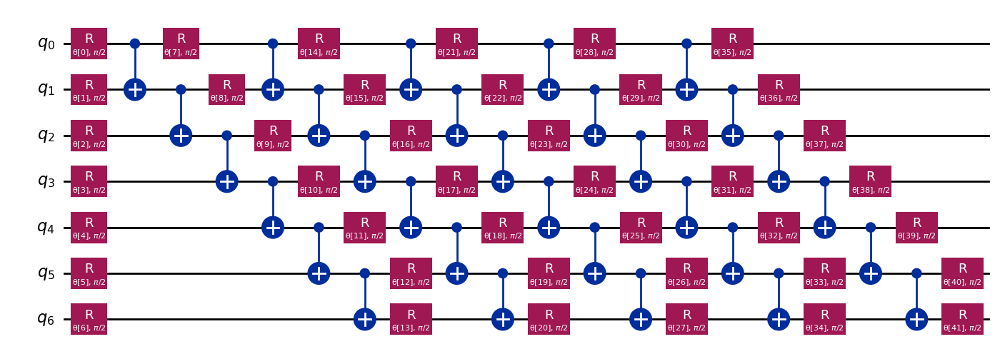

In [6]:
# ================================
# 5. Ansatz y observable
# ================================

from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator

# Ansatz entrenable
ansatz = real_amplitudes(
    num_qubits=n_qubits,
    reps=5,
    entanglement="linear"
)

parametros_ansatz = list(ansatz.parameters)

print("Número de parámetros entrenables:", len(parametros_ansatz))

# Observable Z sobre el qubit 0
# La salida estará entre -1 y 1
observable = SparsePauliOp.from_list([
    ("I" * (n_qubits - 1) + "Z", 1.0)
])

estimator = StatevectorEstimator()

ansatz.decompose().draw("mpl")

In [7]:
# ================================
# 6. Normalización de amplitudes
# ================================

def normalizar_amplitudes(x, n_qubits):
    target_dim = 2 ** n_qubits

    x = np.asarray(x, dtype=np.float64).flatten()

    if len(x) < target_dim:
        x = np.pad(x, (0, target_dim - len(x)), mode="constant")

    elif len(x) > target_dim:
        raise ValueError(
            f"El vector tiene dimensión {len(x)}, pero con {n_qubits} qubits "
            f"solo se permiten {target_dim} amplitudes."
        )

    norm = np.linalg.norm(x)

    if norm == 0:
        x_norm = np.zeros(target_dim, dtype=np.float64)
        x_norm[0] = 1.0
        return x_norm

    x_norm = x / norm

    # Segunda normalización para evitar errores numéricos de Qiskit
    x_norm = x_norm / np.sqrt(np.sum(np.abs(x_norm) ** 2))

    return x_norm


In [8]:
# ================================
# 7. Forward del modelo cuántico
# ================================

def forward(X_batch, weight_params, estimator, observable):

    predicciones = []

    for x in X_batch:

        amplitudes = normalizar_amplitudes(x, n_qubits)

        qc = QuantumCircuit(n_qubits)

        # Amplitude encoding
        qc.initialize(amplitudes, range(n_qubits))

        # Agregar ansatz
        circuito = qc.compose(ansatz)

        # Asignar parámetros entrenables
        param_dict = dict(zip(parametros_ansatz, weight_params))
        circuito = circuito.assign_parameters(param_dict)

        # Evaluación con StatevectorEstimator
        resultado = estimator.run([
            (circuito, observable)
        ]).result()

        pred = resultado[0].data.evs
        pred = float(np.asarray(pred).reshape(-1)[0])

        predicciones.append(pred)

    return np.array(predicciones, dtype=np.float64)

In [9]:
# ================================
# Prueba rápida del forward
# ================================

np.random.seed(42)

weight_params_test = np.random.uniform(
    -0.15,
    0.15,
    len(parametros_ansatz)
)

preds_prueba = forward(
    X_train[:5],
    weight_params_test,
    estimator,
    observable
)

print("Predicciones de prueba:")
print(preds_prueba)

Predicciones de prueba:
[-0.64807205 -0.2560668   0.62765506 -0.29107261 -0.20337275]


In [10]:
# ================================
# 8. Loss ponderada
# ================================

objective_func_vals = []

def weighted_mse(preds, target_vec):

    preds = np.asarray(preds, dtype=np.float64).reshape(-1)
    target_vec = np.asarray(target_vec, dtype=int).reshape(-1)

    n_FM = np.sum(target_vec == 1)
    n_AFM = np.sum(target_vec == -1)

    w_FM = 1 / n_FM if n_FM > 0 else 0
    w_AFM = 1 / n_AFM if n_AFM > 0 else 0

    weights = np.where(target_vec == 1, w_FM, w_AFM)

    loss = np.sum(weights * (preds - target_vec) ** 2) / np.sum(weights)

    return float(loss)


def mse_loss_weights(weight_params, X_batch, y_batch):

    preds = forward(
        X_batch,
        weight_params,
        estimator,
        observable
    )

    loss = weighted_mse(preds, y_batch)

    objective_func_vals.append(float(loss))

    return float(loss)

In [11]:
# ================================
# 9. Evaluar loss en un conjunto fijo
# ================================

def predecir_continuo(X_data, weight_params, batch_size_pred=100):

    y_pred_continuo = []

    for i in range(0, len(X_data), batch_size_pred):

        X_batch = X_data[i:i + batch_size_pred]

        preds = forward(
            X_batch,
            weight_params,
            estimator,
            observable
        )

        y_pred_continuo.extend(preds)

    return np.array(y_pred_continuo, dtype=np.float64)


def evaluar_loss(weight_params, X_data, y_data, batch_size_eval=100):

    preds = predecir_continuo(
        X_data,
        weight_params,
        batch_size_pred=batch_size_eval
    )

    loss = weighted_mse(preds, y_data)

    return float(loss)

In [12]:
# ================================
# 10. Entrenamiento
# ================================

objective_func_vals = []
loss_por_batch = []
val_loss_por_batch = []

batch_size = 100
num_epochs = 5
maxiter_por_batch = 1000

num_samples = len(X_train)

np.random.seed(42)

weight_params = np.random.uniform(
    -0.15,
    0.15,
    len(parametros_ansatz)
)

print("Número de muestras:", num_samples)
print("Número de parámetros:", len(weight_params))

# Early stopping
best_val_loss = np.inf
best_weights = weight_params.copy()

patience = 6
min_delta = 1e-4
contador_sin_mejora = 0

detener_entrenamiento = False

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")

    indices = np.random.permutation(num_samples)

    X_train_shuffled = X_train[indices]
    y_train_shuffled = y_train[indices]

    for i in range(0, num_samples, batch_size):

        X_train_batch = X_train_shuffled[i:i + batch_size]
        y_train_batch = y_train_shuffled[i:i + batch_size]

        print(f"\nBatch {i // batch_size + 1}")

        res = minimize(
            mse_loss_weights,
            weight_params,
            args=(X_train_batch, y_train_batch),
            method="COBYLA",
            options={
                "maxiter": maxiter_por_batch,
                "rhobeg": 0.05,
                "tol": 1e-3
            }
        )

        weight_params = res.x
        loss_por_batch.append(res.fun)

        val_loss = evaluar_loss(
            weight_params,
            X_val,
            y_val,
            batch_size_eval=100
        )

        val_loss_por_batch.append(val_loss)

        print(f"Loss batch: {res.fun:.6f}")
        print(f"Loss validación: {val_loss:.6f}")

        if val_loss < best_val_loss - min_delta:

            best_val_loss = val_loss
            best_weights = weight_params.copy()
            contador_sin_mejora = 0

            print("Mejoró validación. Pesos guardados.")

        else:

            contador_sin_mejora += 1

            print(f"No mejoró. Paciencia: {contador_sin_mejora}/{patience}")

        if contador_sin_mejora >= patience:

            print("\nEarly stopping activado.")
            detener_entrenamiento = True
            break

    if detener_entrenamiento:
        break


# Recuperar mejores pesos encontrados
weight_params = best_weights.copy()

print("\nEntrenamiento terminado.")
print("Mejor loss de validación:", best_val_loss)

Número de muestras: 5116
Número de parámetros: 42

Epoch 1/5

Batch 1
Loss batch: 0.661875
Loss validación: 0.957683
Mejoró validación. Pesos guardados.

Batch 2
Loss batch: 0.646255
Loss validación: 0.971247
No mejoró. Paciencia: 1/6

Batch 3
Loss batch: 0.767739
Loss validación: 0.985129
No mejoró. Paciencia: 2/6

Batch 4
Loss batch: 0.633672
Loss validación: 0.999107
No mejoró. Paciencia: 3/6

Batch 5
Loss batch: 0.692682
Loss validación: 0.951637
Mejoró validación. Pesos guardados.

Batch 6
Loss batch: 0.714973
Loss validación: 0.985611
No mejoró. Paciencia: 1/6

Batch 7
Loss batch: 0.679903
Loss validación: 1.006456
No mejoró. Paciencia: 2/6

Batch 8
Loss batch: 0.669538
Loss validación: 0.965603
No mejoró. Paciencia: 3/6

Batch 9
Loss batch: 0.720216
Loss validación: 0.927061
Mejoró validación. Pesos guardados.

Batch 10
Loss batch: 0.665270
Loss validación: 0.941833
No mejoró. Paciencia: 1/6

Batch 11
Loss batch: 0.753866
Loss validación: 0.922233
Mejoró validación. Pesos guarda

In [13]:
import os
import json
import pickle
import numpy as np
import pandas as pd
from qiskit import qpy

# ============================================
# Ruta de guardado
# ============================================

ruta_modelo = r"C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6M1P1"

os.makedirs(ruta_modelo, exist_ok=True)

# Asegurar que se guardan los mejores pesos
weight_params = best_weights.copy()

# ============================================
# 1. Guardar pesos entrenados
# ============================================

np.save(
    os.path.join(ruta_modelo, "pesos_modelo_cuantico.npy"),
    weight_params
)

# ============================================
# 2. Guardar scaler
# ============================================

with open(os.path.join(ruta_modelo, "scaler.pkl"), "wb") as f:
    pickle.dump(scaler, f)

# ============================================
# 3. Guardar ansatz
# ============================================

with open(os.path.join(ruta_modelo, "ansatz.qpy"), "wb") as f:
    qpy.dump(ansatz, f)

# ============================================
# 4. Guardar observable
# ============================================

with open(os.path.join(ruta_modelo, "observable.pkl"), "wb") as f:
    pickle.dump(observable, f)

# ============================================
# 5. Guardar columnas usadas
# ============================================

feature_columns = list(X_df.columns)

with open(os.path.join(ruta_modelo, "feature_columns.json"), "w") as f:
    json.dump(feature_columns, f, indent=4)

# ============================================
# 6. Guardar configuración
# ============================================

config_modelo = {
    "n_qubits": int(n_qubits),
    "target_dim": int(target_dim),
    "n_features": int(n_features),
    "num_parametros": int(len(weight_params)),
    "encoding": "amplitude_encoding",
    "ansatz": "real_amplitudes",
    "entanglement": "circular",
    "loss_fase_1": "weighted_mse",
    "optimizer": "COBYLA",
    "batch_size": int(batch_size),
    "num_epochs": int(num_epochs),
    "maxiter_por_batch": int(maxiter_por_batch),
    "labels": {
        "AFM": -1,
        "FM": 1
    },
    "umbral_clasificacion": 0
}

with open(os.path.join(ruta_modelo, "config_modelo.json"), "w") as f:
    json.dump(config_modelo, f, indent=4)

# ============================================
# 7. Guardar historial de pérdidas
# ============================================

np.savez_compressed(
    os.path.join(ruta_modelo, "historial_perdidas_fase1.npz"),
    objective_func_vals=np.array(objective_func_vals),
    loss_por_batch=np.array(loss_por_batch),
    val_loss_por_batch=np.array(val_loss_por_batch)
)

print("Modelo guardado correctamente en:")
print(ruta_modelo)

Modelo guardado correctamente en:
C:\Users\javie\OneDrive\Escritorio\Tesis4\Modelos\Entrega6M1P1


In [14]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# =====================================================
# Usar SOLO los mejores pesos del entrenamiento que diste
# =====================================================

weight_params_eval = best_weights.copy()

# Predicciones continuas en test
y_pred_continuo = predecir_continuo(
    X_test,
    weight_params_eval,
    batch_size_pred=100
)

# Clasificación con umbral natural 0
y_pred = np.where(y_pred_continuo >= 0, 1, -1)

y_true = y_test.copy()

# Métricas
accuracy = accuracy_score(y_true, y_pred)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

print("===== MÉTRICAS MODELO CUÁNTICO =====")
print("Accuracy:", accuracy)
print("Balanced Accuracy:", balanced_acc)
print("Precision macro:", precision_macro)
print("Recall macro:", recall_macro)
print("F1 macro:", f1_macro)

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

===== MÉTRICAS MODELO CUÁNTICO =====
Accuracy: 0.621875
Balanced Accuracy: 0.6003891689929293
Precision macro: 0.591206326953158
Recall macro: 0.6003891689929293
F1 macro: 0.5913941185235652

Classification Report:

              precision    recall  f1-score   support

         AFM       0.43      0.54      0.48       517
          FM       0.75      0.66      0.70      1083

    accuracy                           0.62      1600
   macro avg       0.59      0.60      0.59      1600
weighted avg       0.65      0.62      0.63      1600



In [15]:
# =====================================================
# Baseline: predecir siempre la clase mayoritaria
# =====================================================

clase_mayoritaria = Counter(y_true).most_common(1)[0][0]

y_baseline = np.full_like(y_true, clase_mayoritaria)

accuracy_base = accuracy_score(y_true, y_baseline)
balanced_acc_base = balanced_accuracy_score(y_true, y_baseline)
precision_macro_base = precision_score(y_true, y_baseline, average="macro", zero_division=0)
recall_macro_base = recall_score(y_true, y_baseline, average="macro", zero_division=0)
f1_macro_base = f1_score(y_true, y_baseline, average="macro", zero_division=0)

print("===== MÉTRICAS BASELINE =====")
print("Clase mayoritaria:", clase_mayoritaria)
print("Accuracy baseline:", accuracy_base)
print("Balanced Accuracy baseline:", balanced_acc_base)
print("Precision macro baseline:", precision_macro_base)
print("Recall macro baseline:", recall_macro_base)
print("F1 macro baseline:", f1_macro_base)

print("\nClassification Report baseline:\n")
print(classification_report(
    y_true,
    y_baseline,
    labels=[-1, 1],
    target_names=["AFM", "FM"],
    zero_division=0
))

===== MÉTRICAS BASELINE =====
Clase mayoritaria: 1
Accuracy baseline: 0.676875
Balanced Accuracy baseline: 0.5
Precision macro baseline: 0.3384375
Recall macro baseline: 0.5
F1 macro baseline: 0.4036526276556094

Classification Report baseline:

              precision    recall  f1-score   support

         AFM       0.00      0.00      0.00       517
          FM       0.68      1.00      0.81      1083

    accuracy                           0.68      1600
   macro avg       0.34      0.50      0.40      1600
weighted avg       0.46      0.68      0.55      1600



In [16]:
tabla_metricas = pd.DataFrame({
    "Modelo": ["Baseline clase mayoritaria", "Modelo cuántico MSE"],
    "Accuracy": [accuracy_base, accuracy],
    "Balanced Accuracy": [balanced_acc_base, balanced_acc],
    "Precision macro": [precision_macro_base, precision_macro],
    "Recall macro": [recall_macro_base, recall_macro],
    "F1 macro": [f1_macro_base, f1_macro]
})

display(tabla_metricas)

,Modelo,Accuracy,Balanced Accuracy,Precision macro,Recall macro,F1 macro
0,Baseline clase mayoritaria,0.676875,0.500000,0.338438,0.500000,0.403653
1,Modelo cuántico MSE,0.621875,0.600389,0.591206,0.600389,0.591394


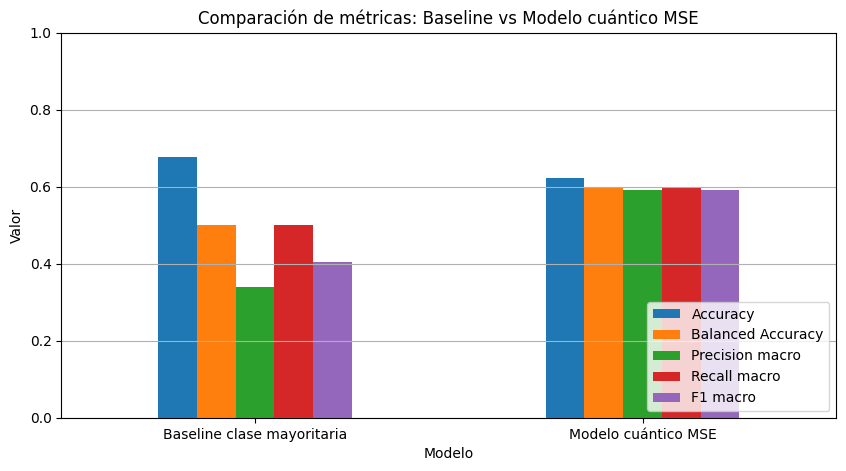

In [17]:
metricas_plot = tabla_metricas.set_index("Modelo")

ax = metricas_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparación de métricas: Baseline vs Modelo cuántico MSE")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.grid(axis="y")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

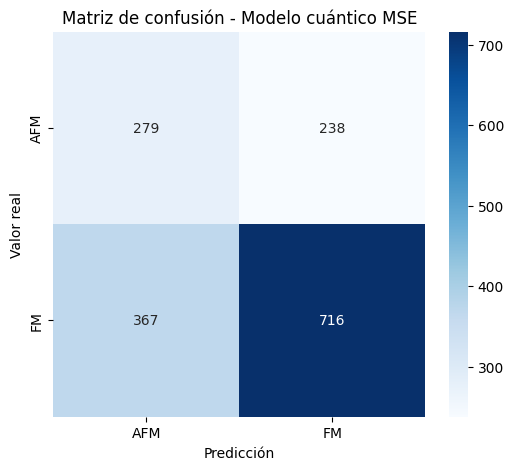

In [18]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[-1, 1]
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["AFM", "FM"],
    yticklabels=["AFM", "FM"]
)

plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.title("Matriz de confusión - Modelo cuántico MSE")
plt.show()

===== SALIDAS CONTINUAS =====
Mínimo pred: -0.8372202393258766
Máximo pred: 0.8374972544567874
Promedio pred: 0.04666508723818986
Desviación pred: 0.27977913284461503

Media AFM: -0.03503776961730655
Media FM: 0.08566820542313136

Std AFM: 0.2744708638643072
Std FM: 0.27381188873554146

AFM correctamente negativos: 0.539651837524178
FM correctamente positivos: 0.6611265004616805


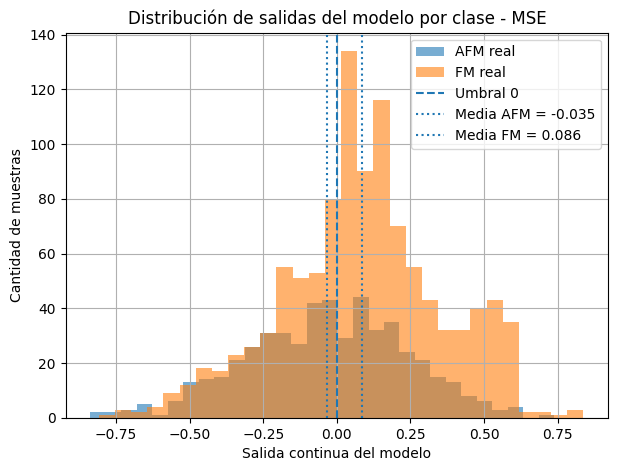

In [19]:
media_afm = np.mean(y_pred_continuo[y_true == -1])
media_fm = np.mean(y_pred_continuo[y_true == 1])

std_afm = np.std(y_pred_continuo[y_true == -1])
std_fm = np.std(y_pred_continuo[y_true == 1])

afm_correctos = np.mean(y_pred_continuo[y_true == -1] < 0)
fm_correctos = np.mean(y_pred_continuo[y_true == 1] >= 0)

print("===== SALIDAS CONTINUAS =====")
print("Mínimo pred:", np.min(y_pred_continuo))
print("Máximo pred:", np.max(y_pred_continuo))
print("Promedio pred:", np.mean(y_pred_continuo))
print("Desviación pred:", np.std(y_pred_continuo))

print("\nMedia AFM:", media_afm)
print("Media FM:", media_fm)

print("\nStd AFM:", std_afm)
print("Std FM:", std_fm)

print("\nAFM correctamente negativos:", afm_correctos)
print("FM correctamente positivos:", fm_correctos)

plt.figure(figsize=(7, 5))

plt.hist(
    y_pred_continuo[y_true == -1],
    bins=30,
    alpha=0.6,
    label="AFM real"
)

plt.hist(
    y_pred_continuo[y_true == 1],
    bins=30,
    alpha=0.6,
    label="FM real"
)

plt.axvline(0, linestyle="--", label="Umbral 0")
plt.axvline(media_afm, linestyle=":", label=f"Media AFM = {media_afm:.3f}")
plt.axvline(media_fm, linestyle=":", label=f"Media FM = {media_fm:.3f}")

plt.xlabel("Salida continua del modelo")
plt.ylabel("Cantidad de muestras")
plt.title("Distribución de salidas del modelo por clase - MSE")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
loss_por_batch
val_loss_por_batch

[0.9576829990652023,
 0.9712469184053457,
 0.9851291055857907,
 0.9991073296056787,
 0.9516365378020012,
 0.9856110047566319,
 1.006455934831512,
 0.9656026796908728,
 0.9270605977604581,
 0.9418334329498667,
 0.9222325077052961,
 0.9774832932956596,
 0.9602408222237261,
 0.9878352149399,
 0.9849785775219358,
 0.932726145540971,
 0.9755441604794037]

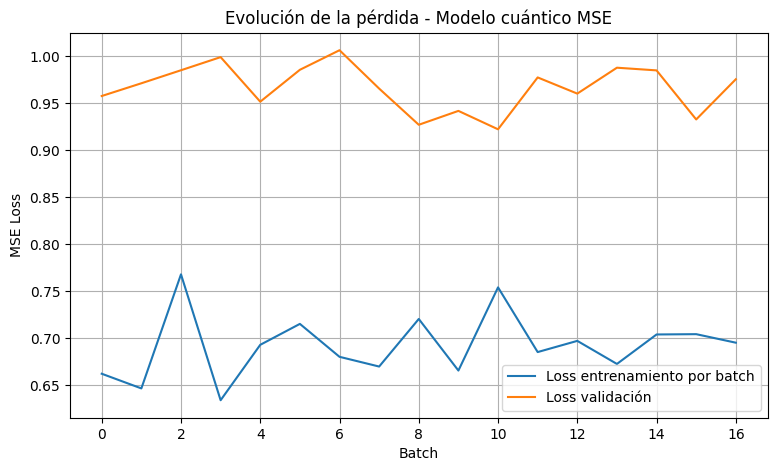

In [21]:
plt.figure(figsize=(9, 5))

plt.plot(loss_por_batch, label="Loss entrenamiento por batch")
plt.plot(val_loss_por_batch, label="Loss validación")

plt.xlabel("Batch")
plt.ylabel("MSE Loss")
plt.title("Evolución de la pérdida - Modelo cuántico MSE")
plt.legend()
plt.grid(True)
plt.show()

In [22]:
mejor_batch = np.argmin(val_loss_por_batch)
mejor_loss = np.min(val_loss_por_batch)

print("Mejor batch interno:", mejor_batch)
print("Mejor batch real:", mejor_batch + 1)
print("Mejor loss validación:", mejor_loss)
print("Última loss validación:", val_loss_por_batch[-1])

Mejor batch interno: 10
Mejor batch real: 11
Mejor loss validación: 0.9222325077052961
Última loss validación: 0.9755441604794037


In [23]:
loss_train_final = evaluar_loss(
    weight_params_eval,
    X_train,
    y_train,
    batch_size_eval=100
)

loss_val_final = evaluar_loss(
    weight_params_eval,
    X_val,
    y_val,
    batch_size_eval=100
)

loss_test_final = evaluar_loss(
    weight_params_eval,
    X_test,
    y_test,
    batch_size_eval=100
)

print("Loss train final:", loss_train_final)
print("Loss validation final:", loss_val_final)
print("Loss test final:", loss_test_final)

Loss train final: 0.9329138633884162
Loss validation final: 0.9222325077052961
Loss test final: 0.9587309710813215
